In [1]:
import xarray as xr
import torch
import numpy as np
import datetime
import cftime
import matplotlib.pyplot as plt
import sys
import re
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean 
import fsspec
import xesmf as xe
from scipy.stats import pearsonr

In [2]:
# --- Configuration ---
# File System
my_key = "XL8EJRUDQ7QPDJSUUC8Q"
my_secret = "2HaAeDBeiyGBxeeS60t6iOrrwgW6iebpiqoYkAHM"
fs = fsspec.filesystem("s3", key = my_key, secret = my_secret, client_kwargs={"endpoint_url": "https://nyu1.osn.mghpcc.org"})
storage_options = {"key": my_key, "secret": my_secret, "client_kwargs": {"endpoint_url": "https://nyu1.osn.mghpcc.org"}}

# Paths
# TRUTH_PATH = "s3://emulators/am16581/data/2025-11/om4_halfdeg_v4/OM4.zarr" 
#TRUTH_PATH = "/pscratch/sd/a/asubel/Ocean_Emulator/scratch/Sample_Rollouts/Half_Degree_Subset.zarr" 
TRUTH_PATH = "/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/onedeg/OM4.zarr"
TRUTH_PATH_BLUR = '/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/blur/om4_onedeg_blur_v8/OM4.zarr'

# PRED_PATH_1 = '/pscratch/sd/a/asubel/Ocean_Emulator/scratch/Sample_Rollouts/halfdeg_eval_preds.zarr'
PRED_PATH_1 = '/global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/Ocean_Emulator/.LOCAL/2025-12-03-samudra_om4_onedeg/predictions.zarr'

# Set PRED_PATH_2 to None if you only want to compare one emulator
PRED_PATH_2 = '/global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/Ocean_Emulator/.LOCAL/2025-12-04-samudra_om4_onedeg_blur_eval/predictions.zarr'

# Analysis & Plotting Config
EMULATOR_1_LABEL = "Emulator WDMSE"
EMULATOR_1_COLOR = "tab:orange"

EMULATOR_2_LABEL = "Emulator WDMSE-blur"
EMULATOR_2_COLOR = "tab:green"

TRUTH_LABEL = "(OM4)"
TRUTH_COLOR = "black"

# Auxiliary Data Paths
LEVS_PATH = '/pscratch/sd/a/asubel/Data/Chapter_2/CM4_CMIP_New.zarr/'
OCEAN_SAMPLE_PATH = '/pscratch/sd/a/asubel/full-model/scratch/ocean_sample.nc'
DEPTHO_PATH = '/pscratch/sd/a/asubel/full-model/scratch/deptho_unfiltered.nc'

# Variable mapping
OCEAN_FIELD_NAME_PREFIXES = {
    'thetao': ['thetao_'], 'so': ['so_'], 'uo': ['uo_'], 'vo': ['vo_'],
    'zos': ['zos'], 'sea_surface_temperature': ['sst'], 'lev': ['idepth_']
}

In [3]:
def concat_levels(ds: xr.Dataset, prefix: str, xg_name: str | None = None, new_coord: None = None) -> xr.DataArray:
    """Concatenates the levels of a 3D variable into a single DataArray."""
    levels = []
    names = []
    level_pattern = re.compile(rf"{prefix}_(\d+)$")
    for name in ds.data_vars:
        match = level_pattern.search(name)
        if match:
            levels.append(int(match.group(1)))
            names.append(name)
    names = sorted(names, key=lambda name: levels[names.index(name)])
    da = xr.concat([ds[name] for name in names], dim="lev")
    da.name = prefix
    if xg_name is not None:
        da.attrs["xg_name"] = xg_name
    if new_coord is not None:
        new_coord_name, new_coord = new_coord
        da[new_coord_name] = new_coord
        da = da.swap_dims({"lev": new_coord_name})
    return da

def extract_basin_masks(ds_with_basin_var):
    """Extracts boolean masks from the integer 'basin' variable."""
    basin_code = ds_with_basin_var['basin']
    return {
        'Atlantic': xr.where(basin_code == 2, 1.0, np.nan),
        'Pacific': xr.where(basin_code == 3, 1.0, np.nan),
        'Indian': xr.where(basin_code == 5, 1.0, np.nan),
        'Southern': xr.where(basin_code == 1, 1.0, np.nan),
    }

def _detrend_linear_torch(data):
    """
    Removes a linear plane of best fit from 4D (B, C, H, W) data.
    """
    B, C, H, W = data.shape
    device = data.device
    dtype = data.dtype
    
    y_coords = torch.linspace(-1, 1, H, device=device, dtype=dtype)
    x_coords = torch.linspace(-1, 1, W, device=device, dtype=dtype)
    Y, X = torch.meshgrid(y_coords, x_coords, indexing='ij')
    
    A = torch.stack([X.flatten(), Y.flatten(), torch.ones_like(X).flatten()], dim=1)
    
    B_prime = B * C
    data_flat = data.reshape(B_prime, H * W)
    

    coeffs, _, _, _ = torch.linalg.lstsq(A, data_flat.T)

    plane = (A @ coeffs.permute(1, 0).unsqueeze(-1)).reshape(B_prime, H, W)
    
    detrended_data = data.reshape(B_prime, H, W) - plane
    
    return detrended_data.reshape(B, C, H, W)


def compute_isotropic_spectrum_torch(data, dx=1.0, dy=1.0, num_bins=None, n_factor = 4,
                                     remove_mean=True, detrend=None, window='Hann',
                                     truncate=True, cutoff_before_bins: bool = True):
    """
    Computes the isotropic 1D power spectrum from 2D (H,W), 3D (B,H,W),
    or 4D (B,C,H,W) data. Matches `xrft.isotropic_power_spectrum(scaling="density")`.

    The output spectrum is computed for each batch and channel element.

    Parameters:
    ----------
    data : torch.Tensor
        Input data tensor. Can be 2D, 3D, or 4D.
    dx : float, optional
        Grid spacing in the x-dimension.
    dy : float, optional
        Grid spacing in the y-dimension.
    num_bins : int, optional
        Number of bins. If None, defaults to min(H, W) // n_factor.
    n_factor : int, optional
        Factor to determine number of bins.
    remove_mean : bool, optional
        If True, removes spatial mean. Overridden by `detrend`.
    detrend : str, optional
        'linear' or 'constant'.
    window : str, optional
        'hann' or 'Hann'.
    truncate : bool, optional
        If True, truncates spectrum at the smallest Nyquist frequency.
    cutoff_before_bins: bool, optional
        If True, truncates the spectrum after already computing the bin locations. Matches xrft
    Returns:
    -------
    k_bins_centers : torch.Tensor
        1D tensor of bin center wavenumbers. Shape: (num_bins,)
    iso_spectrum : torch.Tensor
        1D tensor of the (k * P(k)) spectrum.
        Shape: (B, C, num_bins), (B, num_bins), or (num_bins,)
    """
    
    device = data.device
    dtype = data.dtype
    orig_dim = data.dim()
    
    if orig_dim == 2:
        data = data.reshape(1, 1, *data.shape)  
    elif orig_dim == 3:
        data = data.unsqueeze(1)                
    elif orig_dim != 4:
        raise ValueError("Input data must be 2D, 3D, or 4D (B, C, H, W)")
        
    B, C, H, W = data.shape
    B_prime = B * C 
    Lx = W * dx
    Ly = H * dy
    
    if num_bins is None:
        num_bins = min(H, W) // n_factor 

    if detrend == 'linear':
        data = _detrend_linear_torch(data)
    elif detrend == 'constant' or remove_mean:
        data = data - torch.mean(data, dim=(-2, -1), keepdim=True)

    if window and window.lower() == 'hann':
        win_y = torch.hann_window(H, device=device, dtype=dtype).unsqueeze(1)
        win_x = torch.hann_window(W, device=device, dtype=dtype).unsqueeze(0)
        win_2d = (win_y * win_x).reshape(1, 1, H, W)
        
        window_correction = torch.mean(win_2d**2).item()
        data = data * win_2d
    else:
        window_correction = 1.0

    fft_2d = torch.fft.rfft2(data, norm='forward')
    
    power_2d = torch.abs(fft_2d)**2
    power_2d = power_2d / window_correction
    
    psd_2d = power_2d * (Lx * Ly)
    
    k_x = torch.fft.rfftfreq(W, d=dx, device=device, dtype=dtype)
    k_y = torch.fft.fftfreq(H, d=dy, device=device, dtype=dtype)
    
    k_x_nyq = 1.0 / (2.0 * dx)
    k_y_nyq = 1.0 / (2.0 * dy)

    k_Y, k_X = torch.meshgrid(k_y, k_x, indexing='ij')
    k_mag = torch.sqrt(k_X**2 + k_Y**2)
    
    k_max_domain = k_mag.max()
    
    if truncate and cutoff_before_bins:
        k_max_cutoff = min(k_x_nyq, k_y_nyq)
        k_max = min(k_max_domain, k_max_cutoff)
    else:
        k_max = k_max_domain
        
    k_bins = torch.linspace(0, k_max, num_bins + 1, device=device, dtype=dtype)
    if truncate and not cutoff_before_bins:
        k_max_cutoff = min(k_x_nyq, k_y_nyq) 
        k_max = min(k_max_domain, k_max_cutoff)        
        k_bins = k_bins[k_bins<k_max_cutoff]
        num_bins = k_bins.numel()-1
    k_bins_centers = (k_bins[:-1] + k_bins[1:]) / 2

    k_mag_flat = k_mag.flatten()
    bin_edges = k_bins[1:-1] 
    
    bin_indices = torch.bucketize(k_mag_flat, bin_edges, right=True)
    
    N_flat = k_mag_flat.shape[0]
    psd_flat_batched = psd_2d.reshape(B_prime, N_flat)

    bin_indices_batched = bin_indices.expand(B_prime, -1)
    binned_psd_sum = torch.zeros(B_prime, num_bins, device=device, dtype=dtype)
    binned_psd_sum.scatter_add_(dim=1, index=bin_indices_batched, src=psd_flat_batched)
    binned_counts = torch.bincount(
        bin_indices, 
        minlength=num_bins
    )
    
    binned_counts_safe = binned_counts.float()
    binned_counts_safe[binned_counts_safe == 0] = torch.nan

    iso_psd_binned = binned_psd_sum / binned_counts_safe.unsqueeze(0)
    iso_spectrum = iso_psd_binned * k_bins_centers.unsqueeze(0)
    iso_spectrum = iso_spectrum.reshape(B, C, num_bins)
    iso_spectrum[..., 0] = torch.nan
    
    if orig_dim == 2:
        iso_spectrum = iso_spectrum.squeeze(0).squeeze(0) 
    elif orig_dim == 3:
        iso_spectrum = iso_spectrum.squeeze(1)            
    return k_bins_centers, iso_spectrum

In [4]:
STATIC_GRID_PATH = 's3://emulators/am16581/ocean_static_no_mask_table.zarr'

# 1. Load Truth
if "s3" in TRUTH_PATH:
    data_truth_ocean = xr.open_zarr(TRUTH_PATH, storage_options=storage_options)
else:
    data_truth_ocean = xr.open_zarr(TRUTH_PATH)
    data_truth_ocean_blur = xr.open_zarr(TRUTH_PATH_BLUR,decode_times=True, use_cftime=True)

# 2. Load Emulator 1
data_ocean_1 = xr.open_zarr(PRED_PATH_1).rename({'lat':'y','lon':'x'})

# 3. Load Emulator 2 (Conditional)
data_ocean_2 = None
if PRED_PATH_2 is not None:
    data_ocean_2 = xr.open_zarr(PRED_PATH_2).rename({'lat':'y','lon':'x'})

# 4. Synchronize Time Slices
time_slice_pred = slice(data_ocean_1.time.values[0], data_ocean_1.time.values[-1])
data_truth_ocean = data_truth_ocean.sel(time=time_slice_pred)
data_truth_ocean_blur = data_truth_ocean_blur.sel(time=time_slice_pred)

# 5. Load Aux Data (Levels, Depth)
levs = xr.open_zarr(LEVS_PATH)['lev'].values
ocean_test = xr.open_dataset(OCEAN_SAMPLE_PATH)
#deptho = xr.open_dataset(DEPTHO_PATH)['deptho']

# 6. Calculate Vertical Spacing (dz)
depth_levels = concat_levels(ocean_test, 'idepth', 'levels')
dz_from_data = (depth_levels[1:] - depth_levels[:-1]).data

# 7. Grid Loading & Basin Mask Generation
# We assume grid shape matches the first emulator
shape_processed = (data_ocean_1.y.size, data_ocean_1.x.size)

try:
    print(f"Loading target grid for shape {shape_processed}...")
    target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape_processed[0]}_by_{shape_processed[1]}.zarr"
    target_grid = xr.open_zarr(target_grid_path, storage_options=storage_options)
    
    # Rename coordinates to standard names
    target_grid = target_grid.rename({
        "grid_x": "x_b", "grid_y": "y_b", "grid_xt": "x", "grid_yt": "y",
        "grid_lon": "lon_b", "grid_lat": "lat_b", "grid_lont": "lon", "grid_latt": "lat",
    }).compute()
    
    # --- Basin Mask Generation (New) ---
    print("Loading and regridding basin mask from static grid...")
    ds_static = xr.open_zarr(STATIC_GRID_PATH, storage_options=storage_options)
    
    # Prepare Source (Static Grid)
    ds_source = ds_static[['basin', 'geolat', 'geolon']].rename({'geolat': 'lat', 'geolon': 'lon'})
    
    # Prepare Target (Emulator Grid)
    ds_target = target_grid[['lat', 'lon']]
    
    # Regrid (Nearest Neighbor)
    regridder = xe.Regridder(
        ds_source, 
        ds_target, 
        method='nearest_s2d', 
        periodic=True, 
        filename=None,
        #filename='/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/Ocean_Emulator/basin_weights.nc',
        reuse_weights=False
    )
    basin_regridded = regridder(ds_source['basin'])
    
    # Define Grid Metrics to be attached to all datasets
    # Note: Added 'basin' to this dictionary
    grid_metrics = {
        'dx': (['y','x'], target_grid['lon_b'].diff('x_b')[:-1].values),
        'dy': (['y','x'], target_grid['lat_b'].diff('y_b')[:,:-1].values),
        'areacello': (['y','x'], xe.util.cell_area(target_grid, 6.371e6).values),
        'basin': (['y','x'], basin_regridded.values) 
    }
    
except Exception as e:
    raise ValueError(f'Error loading grid or generating mask for shape {shape_processed}: {e}')

/tmp/ipykernel_1940624/24297105.py:8: DeprecationWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  data_truth_ocean_blur = xr.open_zarr(TRUTH_PATH_BLUR,decode_times=True, use_cftime=True)


Loading target grid for shape (180, 360)...
Loading and regridding basin mask from static grid...


In [5]:
def process_dataset(ds_input, truth_levs, dz_arr, grid_metrics_dict, is_truth=False):
    """Encapsulates the logic to turn raw rollout/truth into a stacked dataset with grid metrics."""
    
    # Initialize basic coordinate structure
    ds_stacked = xr.Dataset(coords={
        'time': (['time'], ds_input.time.values),
        'y': (['y'], ds_input.y.values),
        'x': (['x'], ds_input.x.values),
        'lev': (['lev'], truth_levs),
        'dz': (['lev'], dz_arr),
    })

    # Process 3D vars
    for var in ['uo', 'vo', 'thetao', 'so']:
        prefix = OCEAN_FIELD_NAME_PREFIXES[var][0][:-1]
        data_processed = concat_levels(ds_input, prefix, var).squeeze().transpose('time', 'y', 'x', 'lev').data
        ds_stacked[var] = (['time', 'y', 'x', 'lev'], data_processed)

    # Process 2D vars
    ds_stacked['zos'] = (['time', 'y', 'x'], ds_input['zos'].squeeze().data)

    # Apply Dummy Mask to dz (as done in original notebook)
    ds_stacked['dz'] = (ds_stacked['dz'] * (ds_stacked['vo'].isel(time=0) * 0 + 1)).compute()

    # Add Grid Metrics
    for metric, data in grid_metrics_dict.items():
        ds_stacked[metric] = data
        ds_stacked = ds_stacked.set_coords(metric)

    return ds_stacked

# Process all datasets
dataset_truth = process_dataset(data_truth_ocean, levs, dz_from_data, grid_metrics, is_truth=True)
dataset_truth_blur = process_dataset(data_truth_ocean_blur, levs, dz_from_data, grid_metrics, is_truth=True)
dataset_emu_1 = process_dataset(data_ocean_1, levs, dz_from_data, grid_metrics)

dataset_emu_2 = None
if data_ocean_2 is not None:
    dataset_emu_2 = process_dataset(data_ocean_2, levs, dz_from_data, grid_metrics)


In [6]:
emulators_to_analyze = {
    EMULATOR_1_LABEL: {'ds': dataset_emu_1, 'color': EMULATOR_1_COLOR}
}

if dataset_emu_2 is not None:
    emulators_to_analyze[EMULATOR_2_LABEL] = {'ds': dataset_emu_2, 'color': EMULATOR_2_COLOR}

Here we look at how the ocean takes up heat over the inference rollout. To remove the shorter signal corresponding to seasonality, we remove climatology before computing this values. We look at this over the upper ocean, mid depth, and deep ocean as we expect signals of decreasing strength as we go to the deep ocean. We first compute OHC as  $$OHC(t) = \sum_{k \in Z} \sum_{j} \sum_{i} \rho_0 c_p \theta_{i,j,k,t} \Delta z_{k} A_{i,j}$$

We then compute the anomaly as $$\Delta OHC(t) = OHC(t)-OHC(0)$$

In [7]:
# Constants
RHO = 1035          # Reference density (kg/m^3)
CP = 3850           # Specific heat capacity (J/kg/K)
SCALE_FACTOR = 1e21 # Scale to ZJ (10^21 J)

DEPTH_SLICES = [
    {'min': 0, 'max': 700, 'title': 'Upper Ocean (0-700m)'},
    {'min': 700, 'max': 2000, 'title': 'Mid-Ocean (700-2000m)'},
    {'min': 2000, 'max': 6000, 'title': 'Deep Ocean (2000m+)'},
    {'min':0, 'max':6000, 'title':'Full Ocean'}
]

DEPTH_LAYERS = [
    {'title':'2.5m','index':0},
    {'title':'700m','index':10},
    {'title':'2000m','index':14},
    {'title':'3000m','index':15}
]

# Visualization Settings
VAR_CONFIG = {
    'thetao': {'cmap': cmocean.cm.thermal, 'units': '$^\circ$C', 'label': 'Temperature', 'centered': False},
    'so':     {'cmap': cmocean.cm.haline,  'units': 'psu',       'label': 'Salinity',    'centered': False},
    'zos':    {'cmap': cmocean.cm.balance, 'units': 'm',         'label': 'SSH',         'centered': True},
    'uo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'U-Velocity',  'centered': True},
    'vo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'V-Velocity',  'centered': True},
}

# Configuration
BASINS_TO_PLOT = ['Atlantic', 'Pacific', 'Indian', 'Southern']

In [8]:

def rmse_spatial(truth_map, pred_map, area):
    """Area-weighted RMSE for 2D spatial maps."""
    sq_diff = (truth_map - pred_map)**2
    
    # Mask weights where data is missing
    weights = area.where(sq_diff.notnull())
    
    numerator = (sq_diff * weights).sum(['y', 'x'])
    denominator = weights.sum(['y', 'x'])
    
    return np.sqrt(numerator / denominator).values.item()


Here we look at the mean bias in each major ocean basin. This bias is computed as the difference between the mean state of the emulator and the mean state of OM4, as such this can average out a lot of errors.

Calculating Truth Zonal Profiles...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self


Generating Zonal Bias Plot for Emulator WDMSE...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/tmp/ipykernel_209859/302065362.py:72: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/tmp/ipykernel_209859/302065362.py:72: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/tmp/ipykernel_209859/302065362.py:72: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time'

Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')


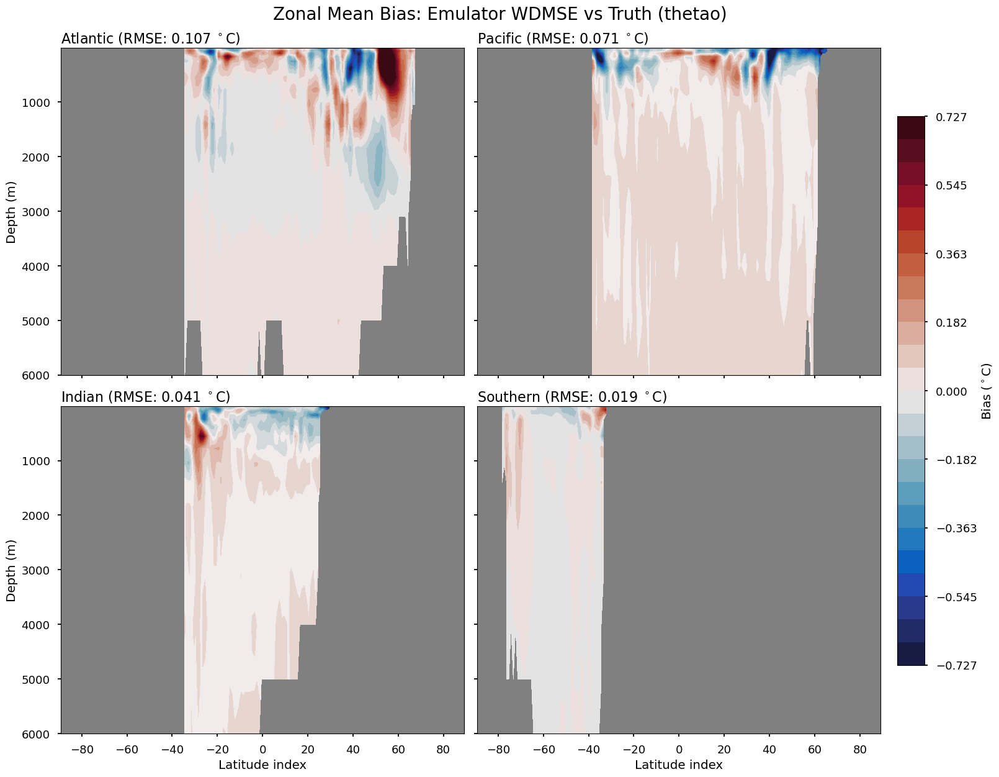


Generating Zonal Bias Plot for Emulator WDMSE-blur...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/tmp/ipykernel_209859/302065362.py:72: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/tmp/ipykernel_209859/302065362.py:72: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/tmp/ipykernel_209859/302065362.py:72: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time'

Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')


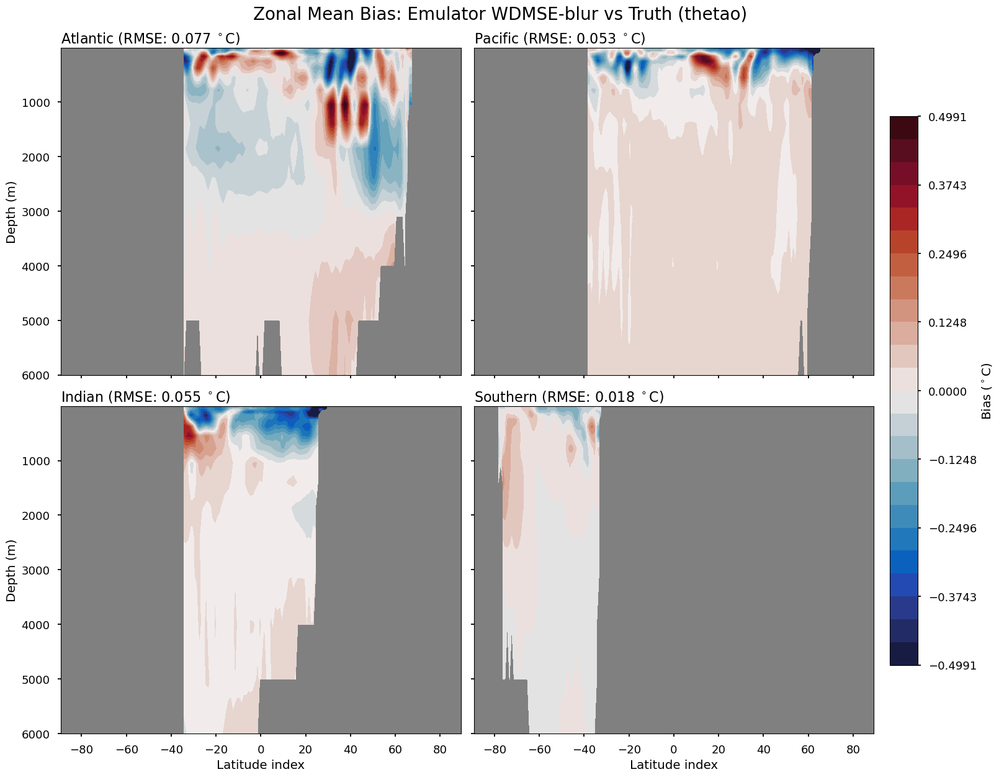

In [9]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean


def calculate_zonal_mean_simple(field_mean, mask, dx, wet):
    """
    Simple Zonal Mean using your exact method.
    Numerator: Sum(Field * Mask * dx)
    Denominator: Sum(Mask * Wet_Truth * dx)
    """
    numerator = (field_mean * mask * dx).sum('x')
    denominator = (mask * wet * dx).sum('x')
    return numerator / denominator

def plot_zonal_bias_comparison(ds_truth, ds_truth_blur, emulators_dict, variable_name, units, masks):
    """Generates a 2x2 plot of zonal mean bias for EACH emulator provided."""
    
    # 0. Setup Truth Metrics (Used for ALL calculations)
    truth_field_mean = ds_truth[variable_name].mean('time')
    truth_blur_field_mean = ds_truth_blur[variable_name].mean('time')
    dx_truth = ds_truth['dx']
    dx_truth_blur = ds_truth_blur['dx']
    
    # Define "Wet" mask from Truth (Matches your snippet: 1 where Data, NaN where Land)
    wet_mask = (ds_truth[variable_name].isel(time=0) * 0 + 1).compute()
    wet_mask_blur = (ds_truth_blur[variable_name].isel(time=0) * 0 + 1).compute()
    
    # 1. Calculate Truth Profiles
    truth_profiles = {}
    truth_profiles_blur = {}
    print("Calculating Truth Zonal Profiles...")
    for basin in BASINS_TO_PLOT:
        truth_profiles[basin] = calculate_zonal_mean_simple(
            truth_field_mean, masks[basin], dx_truth, wet_mask
        ).compute()
        truth_profiles_blur[basin] = calculate_zonal_mean_simple(
            truth_blur_field_mean, masks[basin], dx_truth_blur, wet_mask_blur
        ).compute()


    # 2. Iterate over Emulators
    for label, emu_data in emulators_dict.items():
        ds_emu = emu_data['ds']
        emu_field_mean = ds_emu[variable_name].mean('time')
        
        print(f"\nGenerating Zonal Bias Plot for {label}...")
        
        bias_profiles = {}
        rmse_vals = {}
        
        # Weights for RMSE (Mean across X)
        weight_2d = (ds_truth['dy'] * ds_truth['dz']).mean('x').compute()

        all_biases = []

        for basin in BASINS_TO_PLOT:
            # Calculate Emulator Profile using TRUTH metrics
            prof_emu = calculate_zonal_mean_simple(
                emu_field_mean, masks[basin], dx_truth, wet_mask
            ).compute()
            
            if label==EMULATOR_1_LABEL:
                prof_truth = truth_profiles[basin]
            else:
                prof_truth = truth_profiles_blur[basin]
            
            # Simple Subtraction
            bias = prof_emu - prof_truth
            bias_profiles[basin] = bias.drop('time')
            all_biases.append(bias.values.flatten())
            
            # RMSE Calculation
            sq_diff = bias**2
            rmse = np.sqrt((sq_diff * weight_2d).sum(['y','lev']) / weight_2d.sum(['y','lev']))
            rmse_vals[basin] = rmse.item()

        # Dynamic Color Scaling
        flat_biases = np.concatenate(all_biases)
        flat_biases = flat_biases[~np.isnan(flat_biases)]
        max_abs_bias = np.percentile(np.abs(flat_biases), 98) if len(flat_biases) > 0 else 1.0
        
        norm = colors.Normalize(vmin=-max_abs_bias, vmax=max_abs_bias)
        cmap = cmocean.cm.balance

        # --- Plotting ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            ax = axes[i]
            print(f"Shape: {bias_profiles[basin].shape}")
            print(f"Dims: {bias_profiles[basin].dims}")
            p_mesh = bias_profiles[basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(-max_abs_bias, max_abs_bias, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} (RMSE: {rmse_vals[basin]:.3f} {units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')

        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Bias ({units})")
        fig.suptitle(f"Zonal Mean Bias: {label} vs Truth ({variable_name})", fontsize=20, y=1.03)
        plt.show()
        
# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)

plot_zonal_bias_comparison(
    dataset_truth, 
    dataset_truth_blur,
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks
)

Calculating Truth OHC Zonal Profiles...

Generating OHC Zonal Bias Plot for Emulator WDMSE...
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')


/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')


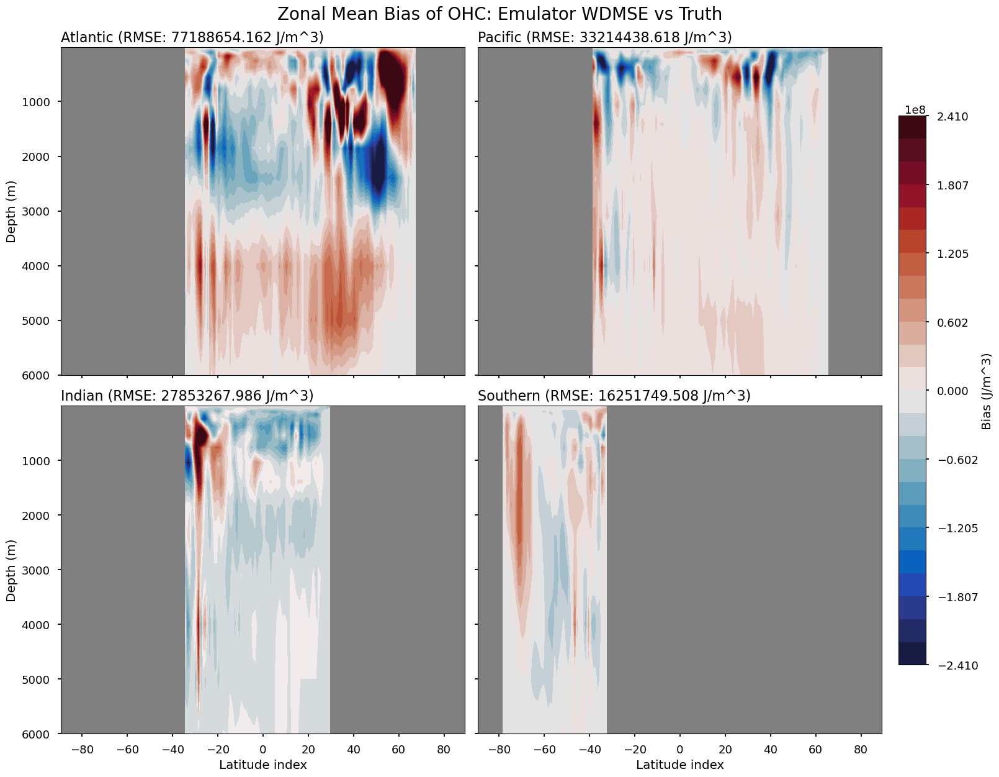


Generating OHC Zonal Bias Plot for Emulator WDMSE-blur...
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')


/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')
/tmp/ipykernel_209859/1177730116.py:79: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bias_profiles[basin] = bias.drop('time')


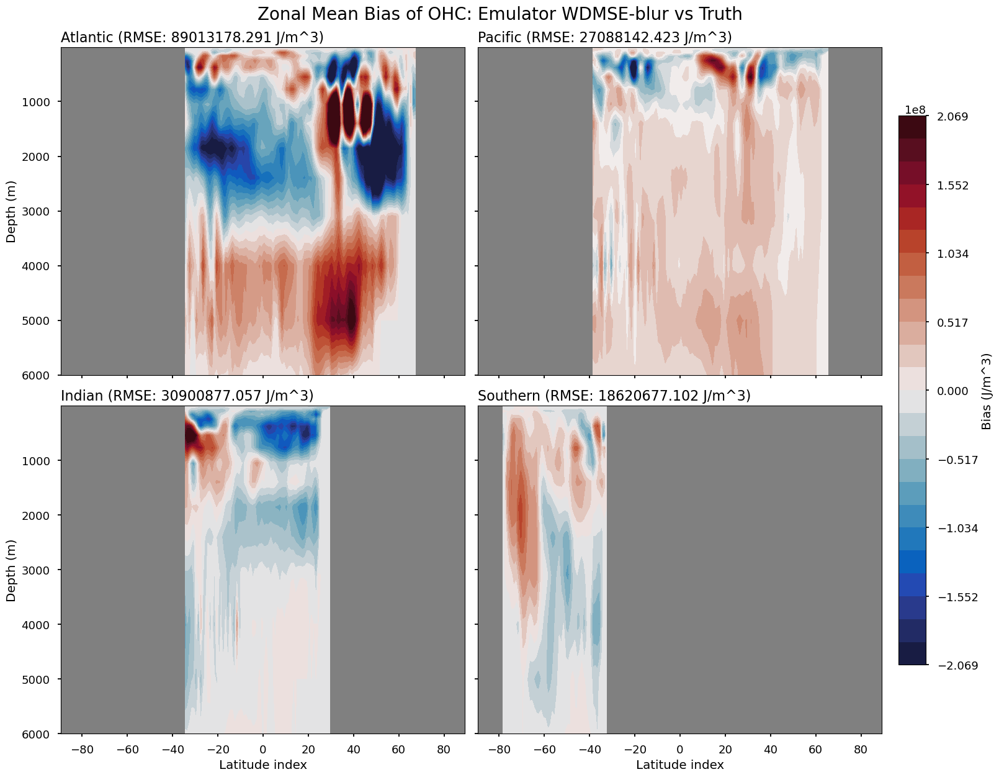

In [10]:
def calculate_ohc_2d(ds):
    """
    Calculates Ocean Heat Content (J/m^2) by integrating thetao over depth.
    Formula: Integral(rho * cp * thetao * dz)
    """
    # Ensure dz is present and correct shape
    # Sum over 'lev' dimension
    ohc = (ds['thetao'] * RHO * CP * ds['dz'])
    ohc.attrs['units'] = 'J/m^3'
    return ohc

def calculate_zonal_mean_2d(field_2d, mask, dx, wet_2d):
    """
    Zonal Mean for a 2D field (e.g. OHC).
    """
    numerator = (field_2d * mask * dx).sum('x')
    denominator = (mask * wet_2d * dx).sum('x')
    return numerator / denominator

def plot_ohc_zonal_bias_comparison(ds_truth, ds_truth_blur, emulators_dict, masks):
    """Generates a 2x2 plot of Zonal Mean OHC Bias (Line Plots) for EACH emulator."""
    
    variable_name = 'OHC'
    units = 'J/m^3'
    
    # 0. Setup Truth Metrics
    # Calculate OHC Mean (Time averaged)
    truth_field_2d = calculate_ohc_2d(ds_truth).mean('time').compute()
    dx_truth = ds_truth['dx']
    truth_blur_field_2d = calculate_ohc_2d(ds_truth_blur).mean('time').compute()
    dx_truth_blur = ds_truth_blur['dx']
    
    # Define 2D "Wet" mask from Truth (surface)
    wet_mask_2d = (ds_truth['thetao'].isel(time=0, lev=0) * 0 + 1).compute()
    wet_blur_mask_2d = (ds_truth_blur['thetao'].isel(time=0, lev=0) * 0 + 1).compute()
    
    # 1. Calculate Truth Zonal Profiles (1D: y)
    truth_profiles = {}
    truth_blur_profiles = {}
    print("Calculating Truth OHC Zonal Profiles...")
    for basin in BASINS_TO_PLOT:
        truth_profiles[basin] = calculate_zonal_mean_2d(
            truth_field_2d, masks[basin], dx_truth, wet_mask_2d
        ).compute()
        truth_blur_profiles[basin] = calculate_zonal_mean_2d(
            truth_blur_field_2d, masks[basin], dx_truth_blur, wet_blur_mask_2d
        ).compute()

    # 2. Iterate over Emulators
    for label, emu_data in emulators_dict.items():
        ds_emu = emu_data['ds']
        # Calculate Emulator OHC Mean
        emu_field_2d = calculate_ohc_2d(ds_emu).mean('time').compute()
        
        print(f"\nGenerating OHC Zonal Bias Plot for {label}...")
        
        bias_profiles = {}

        rmse_vals = {}
        
        # Weights for RMSE (Mean across X)
        weight_2d = (ds_truth['dy'] * ds_truth['dz']).mean('x').compute()

        all_biases = []

        for basin in BASINS_TO_PLOT:
            # Calculate Emulator Profile using TRUTH metrics
            prof_emu = calculate_zonal_mean_2d(
                emu_field_2d, masks[basin], dx_truth, wet_mask_2d
            ).compute()
            
            if label == EMULATOR_1_LABEL:
                prof_truth = truth_profiles[basin]
            if label == EMULATOR_2_LABEL:
                prof_truth = truth_blur_profiles[basin]
            
            # Simple Subtraction
            bias = prof_emu - prof_truth
            bias_profiles[basin] = bias.drop('time')
            all_biases.append(bias.values.flatten())
            
            # RMSE Calculation
            sq_diff = bias**2
            rmse = np.sqrt((sq_diff * weight_2d).sum(['y','lev']) / weight_2d.sum(['y','lev']))
            rmse_vals[basin] = rmse.item()

        # Dynamic Color Scaling
        flat_biases = np.concatenate(all_biases)
        flat_biases = flat_biases[~np.isnan(flat_biases)]
        max_abs_bias = np.percentile(np.abs(flat_biases), 98) if len(flat_biases) > 0 else 1.0
        
        norm = colors.Normalize(vmin=-max_abs_bias, vmax=max_abs_bias)
        cmap = cmocean.cm.balance

        # --- Plotting ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            ax = axes[i]
            print(f"Shape: {bias_profiles[basin].shape}")
            print(f"Dims: {bias_profiles[basin].dims}")
            
            p_mesh = bias_profiles[basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(-max_abs_bias, max_abs_bias, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} (RMSE: {rmse_vals[basin]:.3f} {units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')

        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Bias ({units})")
        fig.suptitle(f"Zonal Mean Bias of OHC: {label} vs Truth", fontsize=20, y=1.03)
        plt.show()

# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)
# basin_masks needs to be derived from 2D basin file or sliced
plot_ohc_zonal_bias_comparison(
    dataset_truth, 
    dataset_truth_blur,
    emulators_to_analyze, 
    masks=basin_masks
)

This is the same bias as above, but seperated into depth levels rather than basins.

Calculating Truth Time Mean and Masks...
Calculating Truth Spatial Maps...

Generating Spatial Bias Maps for Emulator WDMSE...
  > Bias Range (98th percentile): +/- 0.686 $^\circ$C


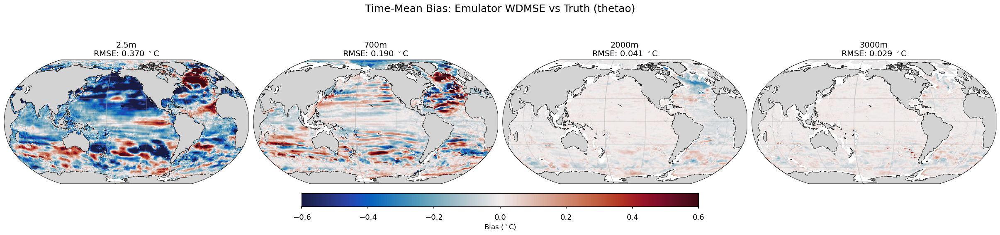


Generating Spatial Bias Maps for Emulator WDMSE-blur...
  > Bias Range (98th percentile): +/- 0.557 $^\circ$C


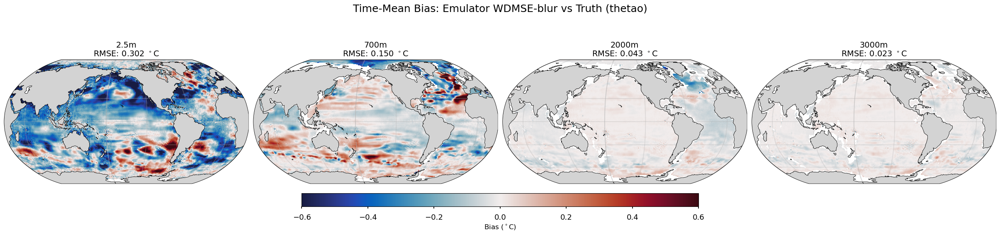

In [11]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Configuration
VARIABLE_TO_PLOT = 'thetao' # Options: 'thetao', 'so'


def calculate_vertical_simple(field, dz, wet_mask, depth_index):
    """
    Calculates the vertical simple map using Truth's geometry.
    Formula: Sum(Field * dz * wet) / Sum(dz * wet) over depth slice.
    """
    # Select depth slices
    f_slice = field.isel(lev=depth_index)
    dz_slice = dz.isel(lev=depth_index)
    wet_slice = wet_mask.isel(lev=depth_index)
    
    numerator = (f_slice * dz_slice * wet_slice)
    denominator = (dz_slice * wet_slice)
    
    return numerator / denominator

def calculate_vertical_mean_simple(field, dz, wet_mask, min_depth, max_depth):
    """
    Calculates the vertical mean map using Truth's geometry.
    Formula: Sum(Field * dz * wet) / Sum(dz * wet) over depth slice.
    """
    # Select depth slices
    f_slice = field.sel(lev=slice(min_depth, max_depth))
    dz_slice = dz.sel(lev=slice(min_depth, max_depth))
    wet_slice = wet_mask.sel(lev=slice(min_depth, max_depth))
    
    numerator = (f_slice * dz_slice * wet_slice).sum('lev')
    denominator = (dz_slice * wet_slice).sum('lev')
    
    return numerator / denominator

def plot_spatial_bias_comparison(ds_truth, ds_truth_blur, emulators_dict, variable_name, units):
    """
    Generates spatial bias maps for each emulator and depth slice.
    """
    
    # 0. Setup Truth Metrics (Used for ALL calculations)
    print("Calculating Truth Time Mean and Masks...")
    truth_field_mean = ds_truth[variable_name].mean('time')
    dz_truth = ds_truth['dz']
    area = ds_truth['areacello']

    truth_field_mean_blur = ds_truth_blur[variable_name].mean('time')
    dz_truth_blur = ds_truth_blur['dz']
    area_blur = ds_truth_blur['areacello']
    
    # Define "Wet" mask from Truth (1 where Data, NaN where Land)
    wet_mask = (ds_truth[variable_name].isel(time=0) * 0 + 1).compute()
    wet_mask_blur = (ds_truth_blur[variable_name].isel(time=0) * 0 + 1).compute()

    # 1. Calculate Truth Maps for all slices
    truth_maps = {}
    truth_blur_maps = {}
    print("Calculating Truth Spatial Maps...")
    for Slices in DEPTH_LAYERS:
        key = Slices['title']
        truth_maps[key] = calculate_vertical_simple(
            truth_field_mean, dz_truth, wet_mask, Slices['index']
        ).compute()
        truth_blur_maps[key] = calculate_vertical_simple(
            truth_field_mean_blur, dz_truth_blur, wet_mask_blur, Slices['index']
        ).compute()

    # 2. Iterate over Emulators
    for label, emu_data in emulators_dict.items():
        ds_emu = emu_data['ds']
        emu_field_mean = ds_emu[variable_name].mean('time')
        
        print(f"\nGenerating Spatial Bias Maps for {label}...")
        
        bias_maps = {}
        rmse_vals = {}
        all_biases_flat = []
        
        for Slices in DEPTH_LAYERS:
            key = Slices['title']
            # Compute Emulator Map using TRUTH metrics (dz, wet_mask)
            map_emu = calculate_vertical_simple(
                emu_field_mean, dz_truth, wet_mask, Slices['index']
            ).compute()
            
            if label == EMULATOR_1_LABEL:
                map_truth = truth_maps[key]
            if label == EMULATOR_2_LABEL:
                map_truth = truth_blur_maps[key]
            
            # Bias
            bias = map_emu - map_truth
            bias_maps[key] = bias
            all_biases_flat.append(bias.values.flatten())
            
            # RMSE
            rmse_vals[key] = rmse_spatial(map_truth, map_emu, area)

        # Dynamic Color Scaling
        flat_data = np.concatenate(all_biases_flat)
        flat_data = flat_data[~np.isnan(flat_data)]
        
        if len(flat_data) > 0:
            max_abs_bias = np.percentile(np.abs(flat_data), 98)
            print(f"  > Bias Range (98th percentile): +/- {max_abs_bias:.3f} {units}")
        else:
            max_abs_bias = 1.0

        vmin, vmax = -max_abs_bias, max_abs_bias
        vmin, vmax = -0.6, 0.6
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        cmap = cmocean.cm.balance

        # --- Plotting ---
        num_slices = len(DEPTH_SLICES)
        fig, axes = plt.subplots(
            1, num_slices, 
            figsize=(6 * num_slices, 5),
            subplot_kw={'projection': ccrs.Robinson(central_longitude=210)},
            constrained_layout=True
        )
        if num_slices == 1: axes = [axes]
        
        for i, Slices in enumerate(DEPTH_LAYERS):
            key = Slices['title']
            ax = axes[i]
            bias = bias_maps[key]
            
            # pcolormesh needs coordinates. 
            p = bias.plot.pcolormesh(
                ax=ax, transform=ccrs.PlateCarree(),
                x='x', y='y',
                cmap=cmap, norm=norm, add_colorbar=False,
                rasterized=True
            )
            
            ax.set_title(f"{key}\nRMSE: {rmse_vals[key]:.3f} {units}", fontsize=14)
            ax.add_feature(cfeature.LAND, zorder=10, edgecolor='black', facecolor='lightgray')
            ax.coastlines(zorder=11)
            ax.gridlines(draw_labels=False, alpha=0.3)

        # Shared Colorbar
        cbar = fig.colorbar(p, ax=axes, orientation='horizontal', shrink=0.4, pad=0.05, aspect=30)
        cbar.set_label(f"Bias ({units})", fontsize=12)
        
        fig.suptitle(f"Time-Mean Bias: {label} vs Truth ({variable_name})", fontsize=18, y=1.1)
        plt.show()

# --- Execution ---
if VARIABLE_TO_PLOT == 'thetao':
    var_label, units = 'Temperature', '$^\circ$C'
else:
    var_label, units = 'Salinity', 'PSU'

plot_spatial_bias_comparison(
    dataset_truth, 
    dataset_truth_blur,
    emulators_to_analyze, 
    variable_name=VARIABLE_TO_PLOT, 
    units=units
)

Plotting some OHC maps

Preparing Truth Metrics...
Calculating Truth OHC Maps...
Calculating OHC Maps for Emulator WDMSE...
Calculating OHC Maps for Emulator WDMSE-blur...


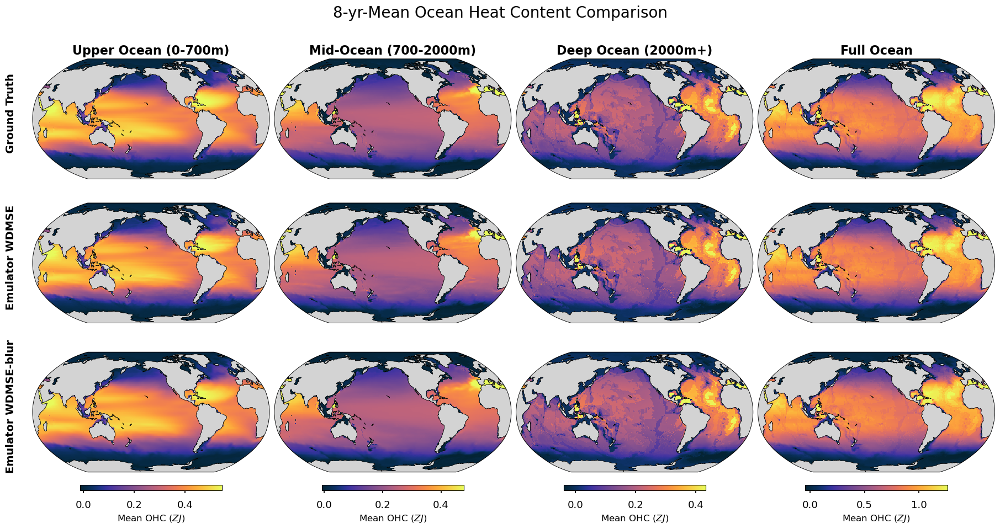

In [12]:
# --------------------------------------------------------------------------------
# BLOCK 12: Mean Ocean Heat Content (OHC) Maps Comparison
# --------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Constants
RHO = 1035          # kg/m^3
CP = 3850           # J/(kg K)
SCALE_GJ = 1e21      # Scale to Gigajoules (10^9 J)


def calculate_ohc_map(dataset, dz, wet_mask, min_depth, max_depth):
    """
    Calculates the Time-Mean OHC map (Vertically Integrated).
    Formula: Sum(rho * cp * thetao * dz) / Scale
    Units: GJ/m^2
    """
    # Select slices
    thetao_slice = dataset['thetao'].sel(lev=slice(min_depth, max_depth))
    dz_slice = dz.sel(lev=slice(min_depth, max_depth))
    wet_slice = wet_mask.sel(lev=slice(min_depth, max_depth))
    
    # 1. Integrate Vertically (Sum over lev)
    # Result is (time, y, x)
    ohc_integrated = (RHO * CP * thetao_slice * dz_slice *dataset['areacello']* wet_slice).sum('lev')
    
    # 2. Time Average
    ohc_mean = ohc_integrated.mean('time')
    
    # 3. Scale
    return ohc_mean / SCALE_GJ

def plot_ohc_mean_comparison(ds_truth, emulators_dict):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    dz_truth = ds_truth['dz']
    # Wet mask from Truth (1 for Ocean, NaN for Land)
    wet_mask = (ds_truth['thetao'].isel(time=0) * 0 + 1).compute()
    
    # 1. Compute Truth Maps (Row 1)
    truth_maps = {}
    print("Calculating Truth OHC Maps...")
    for Slices in DEPTH_SLICES:
        key = Slices['title']
        truth_maps[key] = calculate_ohc_map(
            ds_truth, dz_truth, wet_mask, Slices['min'], Slices['max']
        ).compute()
        
    # 2. Compute Emulator Maps
    emu_maps = {}
    for label, emu_data in emulators_dict.items():
        print(f"Calculating OHC Maps for {label}...")
        ds_emu = emu_data['ds']
        emu_maps[label] = {}
        for Slices in DEPTH_SLICES:
            key = Slices['title']
            # Note: We use Truth's dz and wet_mask to ensure integration domain consistency
            emu_maps[label][key] = calculate_ohc_map(
                ds_emu, dz_truth, wet_mask, Slices['min'], Slices['max']
            ).compute()

    # --- Plotting Setup ---
    datasets = [TRUTH_LABEL] + list(emulators_dict.keys())
    nrows = len(datasets)
    ncols = len(DEPTH_SLICES)
    
    fig, axes = plt.subplots(
        nrows, ncols, 
        figsize=(4.5 * ncols, 3 * nrows),
        subplot_kw={'projection': ccrs.Robinson(central_longitude=210)},
        constrained_layout=True
    )
    
    # Ensure axes is 2D array even if 1 row
    if nrows == 1: axes = np.expand_dims(axes, 0)
    if ncols == 1: axes = np.expand_dims(axes, 1)

    cmap = cmocean.cm.thermal
    
    # 3. Iterate Column-by-Column (Depth Slice) to lock colorbars
    for j, Slices in enumerate(DEPTH_SLICES):
        key = Slices['title']
        
        # Determine Color Scale based on TRUTH (or global max)
        data_truth = truth_maps[key].values
        valid_data = data_truth[~np.isnan(data_truth)]
        
        vmin = np.percentile(valid_data, .5)
        vmax = np.percentile(valid_data, 99.5)
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        
        # Iterate Row-by-Row (Datasets)
        for i, ds_name in enumerate(datasets):
            ax = axes[i, j]
            
            # Select Data
            if ds_name == TRUTH_LABEL:
                data_to_plot = truth_maps[key]
                row_label = "Ground Truth"
            else:
                # Map back from display label to dictionary key if needed, 
                # but here ds_name is the label
                data_to_plot = emu_maps[ds_name][key]
                row_label = ds_name
            
            # Plot
            p = data_to_plot.plot.pcolormesh(
                ax=ax, transform=ccrs.PlateCarree(),
                x='x', y='y',
                cmap=cmap, norm=norm,
                add_colorbar=False,
                rasterized=True
            )
            
            # Styling
            ax.add_feature(cfeature.LAND, zorder=10, edgecolor='black', facecolor='lightgray')
            ax.coastlines(zorder=11)
            
            # Titles/Labels
            if i == 0:
                ax.set_title(key, fontsize=16, fontweight='bold')
            else:
                ax.set_title("")
                
            if j == 0:
                # Add Row Label on the left
                ax.text(-0.07, 0.55, row_label, va='center', ha='right',
                        rotation='vertical', transform=ax.transAxes, 
                        fontsize=14, fontweight='bold')

        # Add ONE Colorbar per Column (at the bottom of the column)
        # We attach it to the last axes in the column
        cbar = fig.colorbar(
            p, ax=axes[:, j], 
            orientation='horizontal', 
            shrink=0.6, pad=0.03, aspect=25
        )
        cbar.set_label(r"Mean OHC ($ZJ$)", fontsize=12)

    fig.suptitle("8-yr-Mean Ocean Heat Content Comparison", fontsize=20, y=1.05)
    plt.show()

# --- Execution ---
plot_ohc_mean_comparison(dataset_truth, emulators_to_analyze)

Preparing Truth Metrics...
Calculating Truth Temperature Maps...


Calculating Temperature Maps for Emulator WDMSE...
Calculating Temperature Maps for Emulator WDMSE-blur...


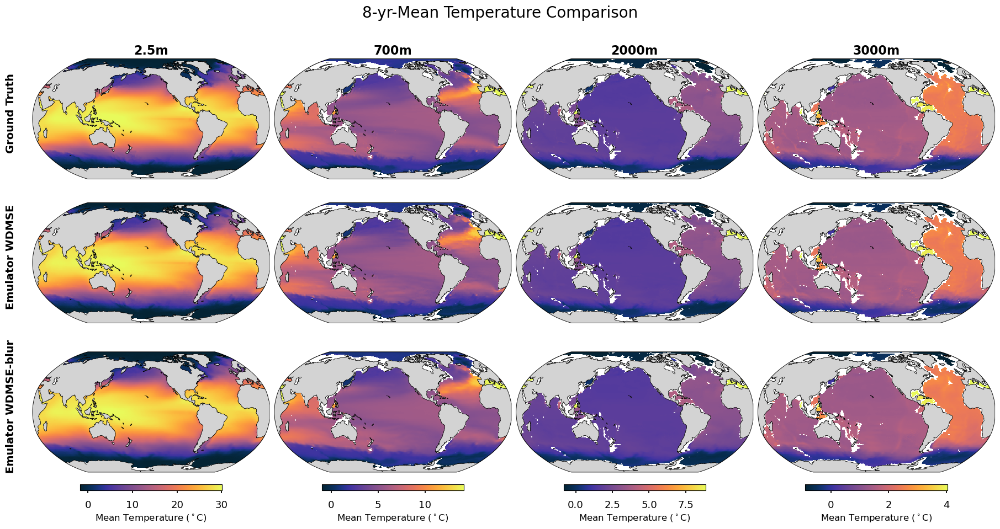

In [13]:
# --------------------------------------------------------------------------------
# BLOCK 12: Mean temperature Maps Comparison
# --------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Configuration ---
VARIABLE_TO_PLOT = 'thetao'  # Options: 'thetao', 'so', 'zos', 'uo', 'vo'


def calculate_temperature_map_layer(dataset, var_name, dz, wet_mask, depth_index, time_idx=None):
    """
    Computes a 2D map for a specific variable at a specific time index.
    - 3D vars: Computes a specific depth.
    - 2D vars: Returns surface field masked by Truth.
    """
    # Select Time Step
    # 2. Time Average
    ds_t = dataset.mean(dim='time')
    #ds_t = dataset.isel(time=time_idx)
    field = ds_t[var_name]
    
    # Select Depth Slice
    f_slice = field.isel(lev=depth_index)
    dz_slice = dz.isel(lev=depth_index)
    wet_slice = wet_mask.isel(lev=depth_index)
    
    # Depth Average
    numerator = (f_slice * dz_slice * wet_slice)
    denominator = (dz_slice * wet_slice)
    result = numerator / denominator
        
    return result.compute()


def calculate_temperature_map(dataset, var_name, dz, wet_mask, d_min, d_max, time_idx=None):
    """
    Computes a 2D map for a specific variable at a specific time index.
    - 3D vars: Computes depth-weighted average.
    - 2D vars: Returns surface field masked by Truth.
    """
    # Select Time Step
    # 2. Time Average
    ds_t = dataset.mean(dim='time')
    #ds_t = dataset.isel(time=time_idx)
    field = ds_t[var_name]
    
    # Check if variable is 3D (has 'lev') or 2D (like zos)
    if 'lev' in field.dims:
        # Select Depth Slice
        f_slice = field.sel(lev=slice(d_min, d_max))
        dz_slice = dz.sel(lev=slice(d_min, d_max))
        wet_slice = wet_mask.sel(lev=slice(d_min, d_max))
        
        # Depth Average
        numerator = (f_slice * dz_slice * wet_slice).sum('lev')
        denominator = (dz_slice * wet_slice).sum('lev')
        result = numerator / denominator
    else:
        # 2D Variable (Use Top Layer of wet mask if wet_mask is 3D)
        if 'lev' in wet_mask.dims:
            mask_2d = wet_mask.isel(lev=0)
        else:
            mask_2d = wet_mask
            
        result = field * mask_2d
        
    return result.compute()


def plot_temperature_mean_comparison(ds_truth, emulators_dict):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    dz_truth = ds_truth['dz']
    # Determine dimensionality for mask
    if 'lev' in ds_truth[VARIABLE_TO_PLOT].dims:
        wet_mask = (ds_truth[VARIABLE_TO_PLOT].isel(time=0) * 0 + 1).compute()
    else:
        # For 2D vars like zos, check for 2D or 3D mask availability
        # Fallback to simple NaN check on the 2D variable itself
        wet_mask = (ds_truth[VARIABLE_TO_PLOT].isel(time=0) * 0 + 1).compute()

    # 1. Compute Truth Maps (Row 1)
    truth_maps = {}
    print("Calculating Truth Temperature Maps...")
    for Slices in DEPTH_LAYERS:
        key = Slices['title']
        truth_maps[key] = calculate_temperature_map_layer(
            ds_truth, VARIABLE_TO_PLOT, dz_truth, wet_mask, Slices['index']
        ).compute()
    # 2. Compute Emulator Maps
    emu_maps = {}
    for label, emu_data in emulators_dict.items():
        print(f"Calculating Temperature Maps for {label}...")
        ds_emu = emu_data['ds']
        emu_maps[label] = {}
        for Slices in DEPTH_LAYERS:
            key = Slices['title']
            # Note: We use Truth's dz and wet_mask to ensure integration domain consistency
            emu_maps[label][key] = calculate_temperature_map_layer(
                ds_emu, VARIABLE_TO_PLOT,  dz_truth, wet_mask, Slices['index']
            ).compute()

    # --- Plotting Setup ---
    datasets = [TRUTH_LABEL] + list(emulators_dict.keys())
    nrows = len(datasets)
    ncols = len(DEPTH_SLICES)
    
    fig, axes = plt.subplots(
        nrows, ncols, 
        figsize=(4.5 * ncols, 3 * nrows),
        subplot_kw={'projection': ccrs.Robinson(central_longitude=210)},
        constrained_layout=True
    )
    
    # Ensure axes is 2D array even if 1 row
    if nrows == 1: axes = np.expand_dims(axes, 0)
    if ncols == 1: axes = np.expand_dims(axes, 1)

    cmap = cmocean.cm.thermal
    
    # 3. Iterate Column-by-Column (Depth Slice) to lock colorbars
    for j, Slices in enumerate(DEPTH_LAYERS):
        key = Slices['title']
        
        # Determine Color Scale based on TRUTH (or global max)
        data_truth = truth_maps[key].values
        valid_data = data_truth[~np.isnan(data_truth)]
        
        vmin = np.percentile(valid_data, .5)
        vmax = np.percentile(valid_data, 99.5)
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        
        # Iterate Row-by-Row (Datasets)
        for i, ds_name in enumerate(datasets):
            ax = axes[i, j]
            
            # Select Data
            if ds_name == TRUTH_LABEL:
                data_to_plot = truth_maps[key]
                row_label = "Ground Truth"
            else:
                # Map back from display label to dictionary key if needed, 
                # but here ds_name is the label
                data_to_plot = emu_maps[ds_name][key]
                row_label = ds_name
            
            # Plot
            p = data_to_plot.plot.pcolormesh(
                ax=ax, transform=ccrs.PlateCarree(),
                x='x', y='y',
                cmap=cmap, norm=norm,
                add_colorbar=False,
                rasterized=True
            )
            
            # Styling
            ax.add_feature(cfeature.LAND, zorder=10, edgecolor='black', facecolor='lightgray')
            ax.coastlines(zorder=11)
            
            # Titles/Labels
            if i == 0:
                ax.set_title(key, fontsize=16, fontweight='bold')
            else:
                ax.set_title("")
                
            if j == 0:
                # Add Row Label on the left
                ax.text(-0.07, 0.55, row_label, va='center', ha='right',
                        rotation='vertical', transform=ax.transAxes, 
                        fontsize=14, fontweight='bold')

        # Add ONE Colorbar per Column (at the bottom of the column)
        # We attach it to the last axes in the column
        cbar = fig.colorbar(
            p, ax=axes[:, j], 
            orientation='horizontal', 
            shrink=0.6, pad=0.03, aspect=25
        )
        cbar.set_label(r"Mean Temperature ($^\circ$C)", fontsize=12)

    fig.suptitle("8-yr-Mean Temperature Comparison", fontsize=20, y=1.05)
    plt.show()

# --- Execution ---
plot_temperature_mean_comparison(dataset_truth, emulators_to_analyze)

Preparing Truth Metrics...
Calculating Truth Zonal Profiles...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Temperature Maps for Emulator WDMSE...

Generating Zonal Bias Plot for Emulator WDMSE...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


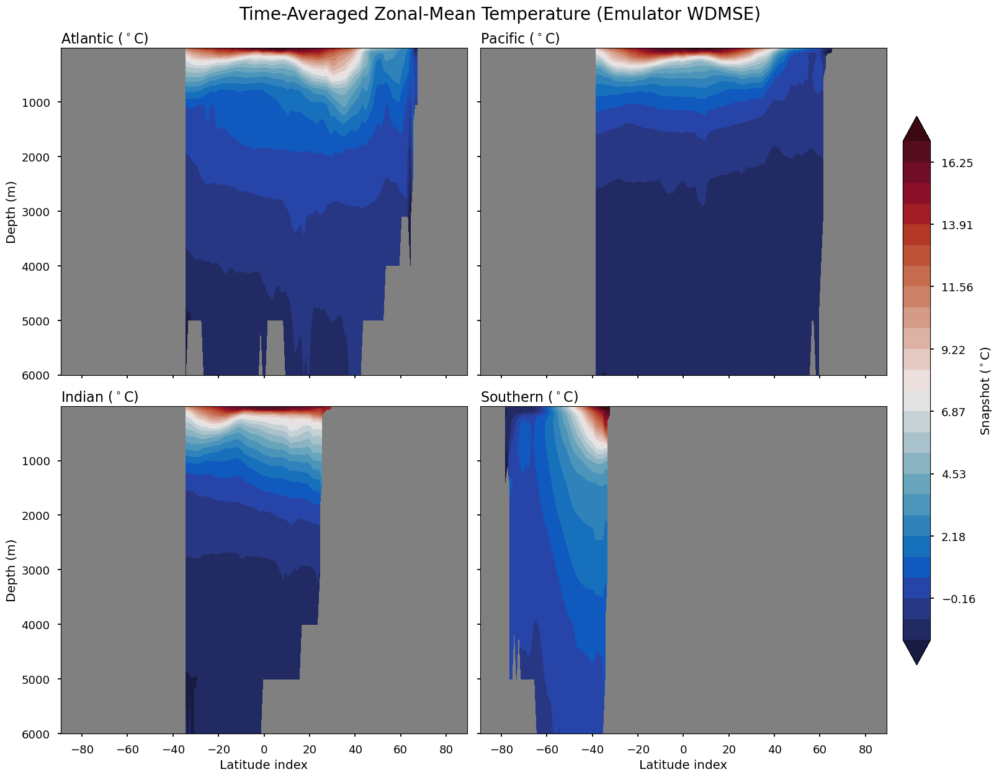

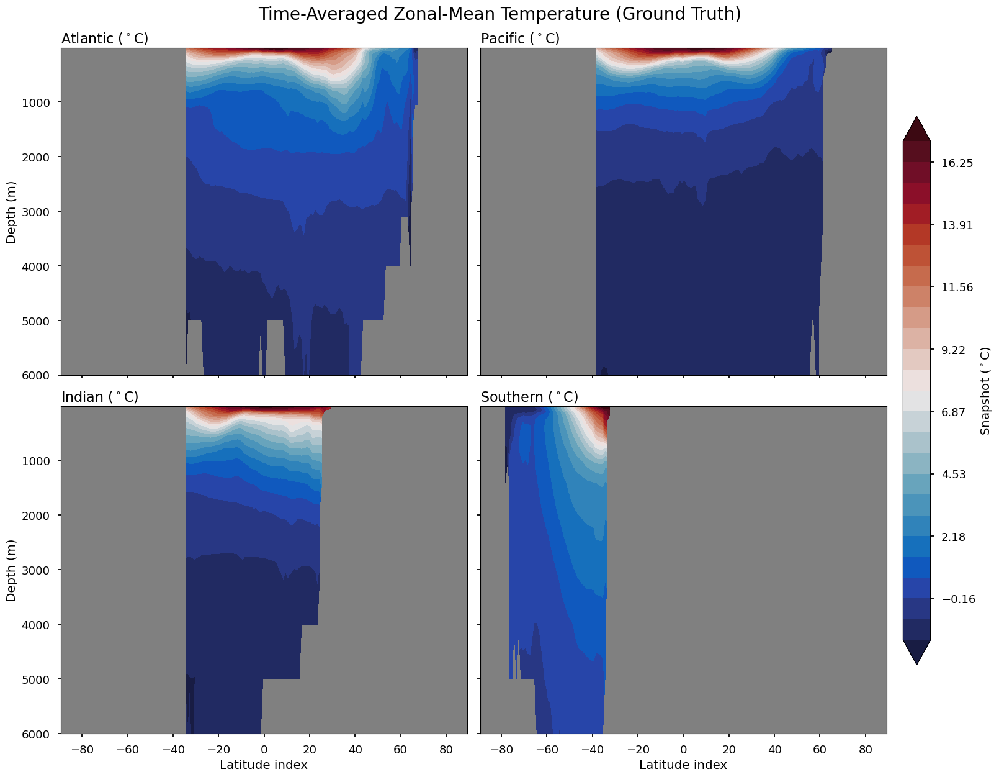

Calculating Temperature Maps for Emulator WDMSE-blur...

Generating Zonal Bias Plot for Emulator WDMSE-blur...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


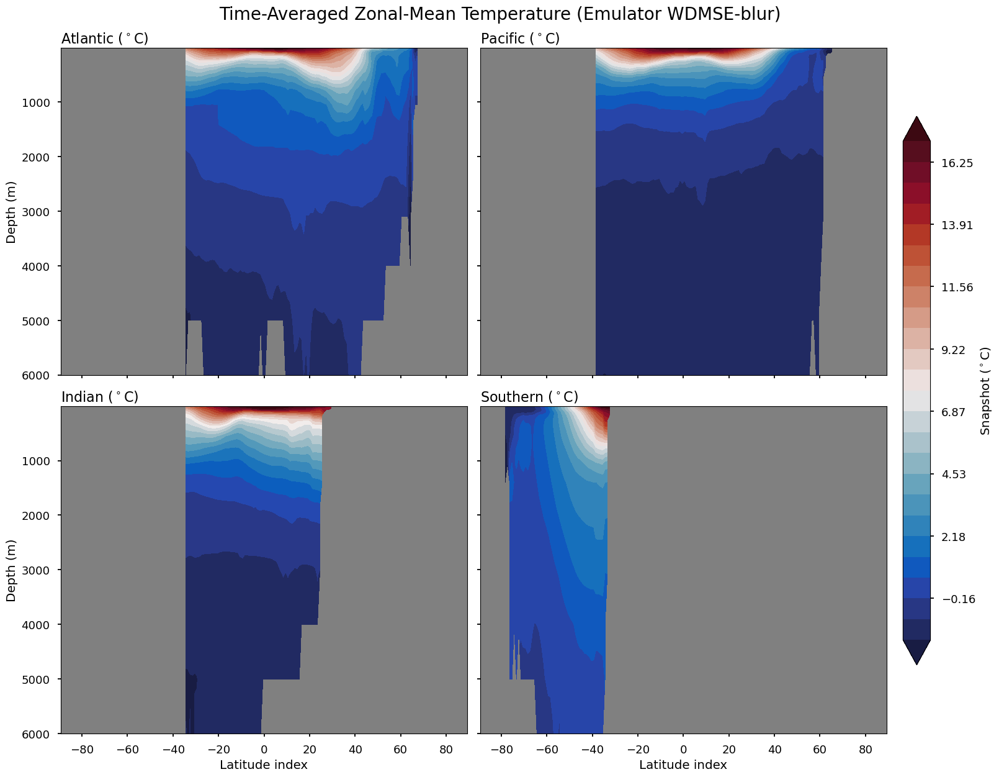

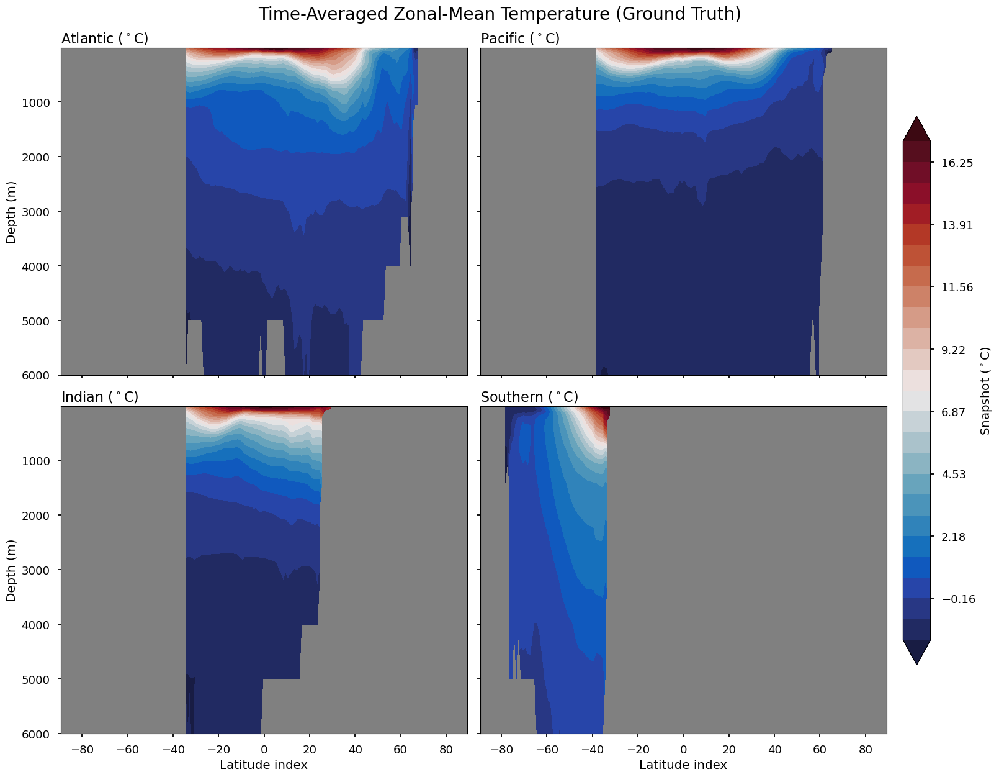

In [14]:
def calculate_zonal_mean(field_mean, mask, dx, wet):
    """
    Simple Zonal Mean using your exact method.
    Numerator: Sum(Field * Mask * dx)
    Denominator: Sum(Mask * Wet_Truth * dx)
    """
    numerator = (field_mean * mask * dx).sum('x')
    denominator = (mask * wet * dx).sum('x')
    return numerator / denominator

def plot_zonal_mean_comparison(ds_truth, emulators_dict,variable_name, units, masks):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    truth_field_mean = ds_truth[variable_name].mean(dim='time')
    dx_truth = ds_truth['dx']
    # Determine dimensionality for mask
    wet_mask = (ds_truth[variable_name].isel(time=0, drop=True) * 0 + 1).compute()
    
    # 1. Compute Truth Maps (Row 1)
    truth_profiles = {}
    print("Calculating Truth Zonal Profiles...")
    for basin in BASINS_TO_PLOT:
        truth_profiles[basin] = calculate_zonal_mean(
            truth_field_mean, masks[basin], dx_truth, wet_mask
        ).compute()

    # 2. Compute Emulator Maps
    emu_maps = {}
    for label, emu_data in emulators_dict.items():
        print(f"Calculating Temperature Maps for {label}...")
        ds_emu = emu_data['ds']
        emu_field_mean = ds_emu[variable_name].mean('time')
        emu_maps[label] = {}

        print(f"\nGenerating Zonal Bias Plot for {label}...")
        
        # Weights for RMSE (Mean across X)
        weight_2d = (ds_truth['dy'] * ds_truth['dz']).mean('x').compute()

        for basin in BASINS_TO_PLOT:
            # Calculate Emulator Profile using TRUTH metrics
            emu_maps[label][basin] = calculate_zonal_mean(
                emu_field_mean, masks[basin], dx_truth, wet_mask
            ).compute()

        # --- Plotting ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 98)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)
            cmap = cmocean.cm.balance

            ax = axes[i]
            p_mesh = emu_maps[label][basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Time-Averaged Zonal-Mean Temperature ({label})", fontsize=20, y=1.03)
        plt.show()

        # --- Plotting ground truth ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 98)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)

            ax = axes[i]
            p_mesh = truth_profiles[basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Time-Averaged Zonal-Mean Temperature (Ground Truth)", fontsize=20, y=1.03)
        plt.show()

# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)

plot_zonal_mean_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks
)


Preparing Truth Metrics...
Calculating Truth Zonal Profiles...
Calculating OHC Maps for Emulator WDMSE...

Generating Zonal Mean Plot for Emulator WDMSE...


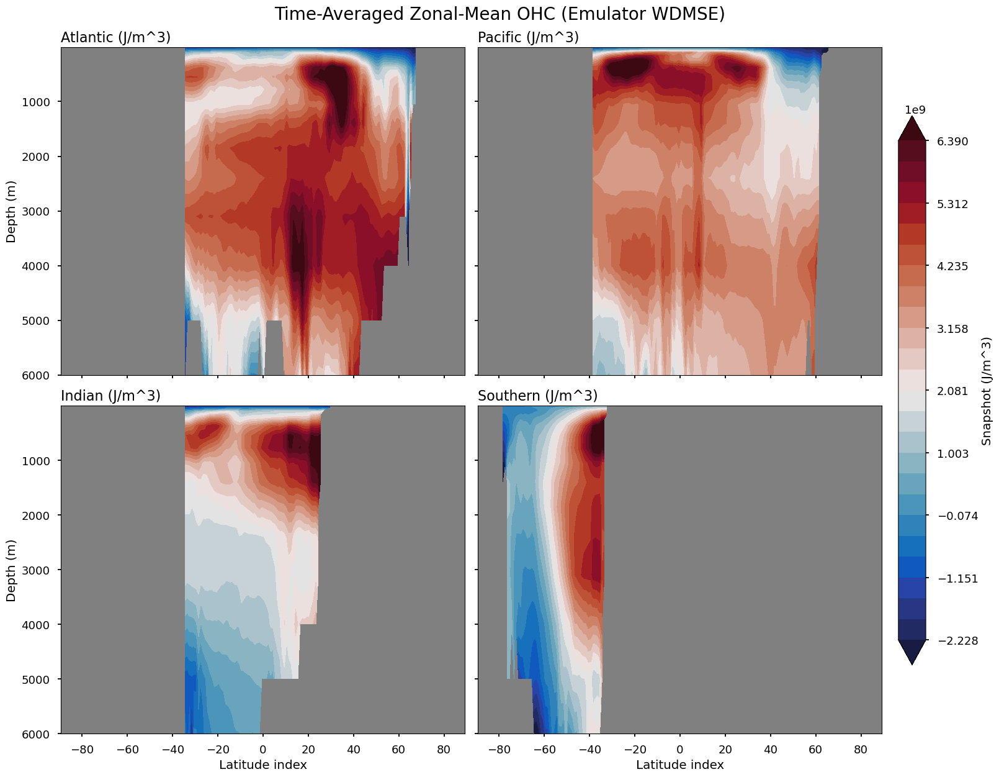

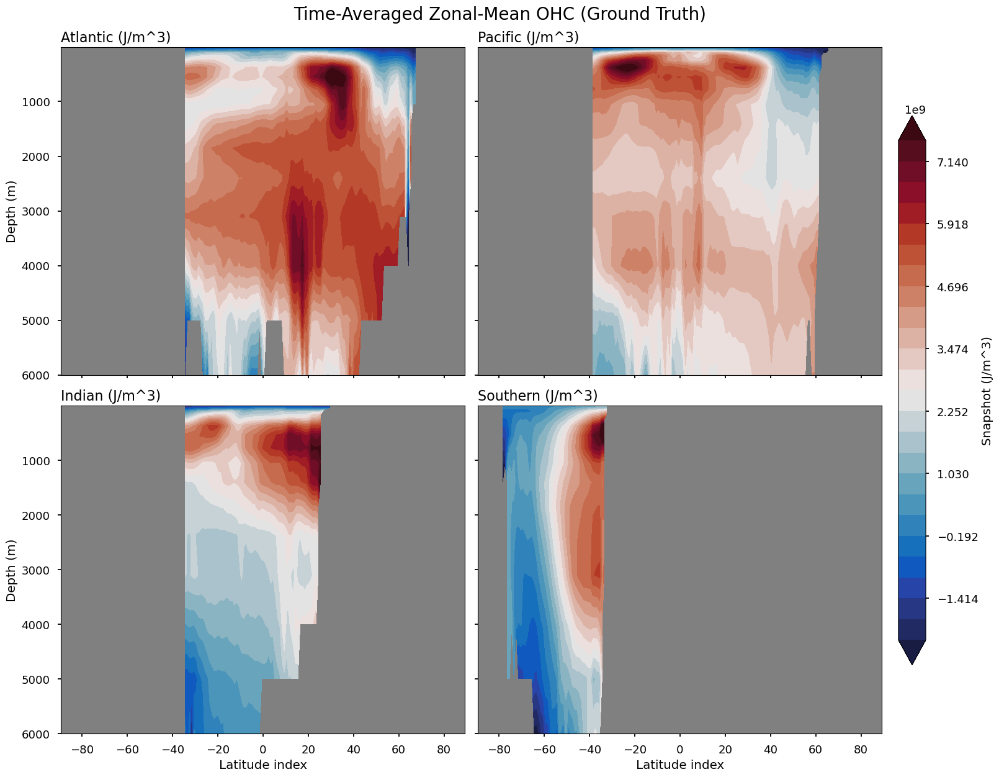

Calculating OHC Maps for Emulator WDMSE-blur...

Generating Zonal Mean Plot for Emulator WDMSE-blur...


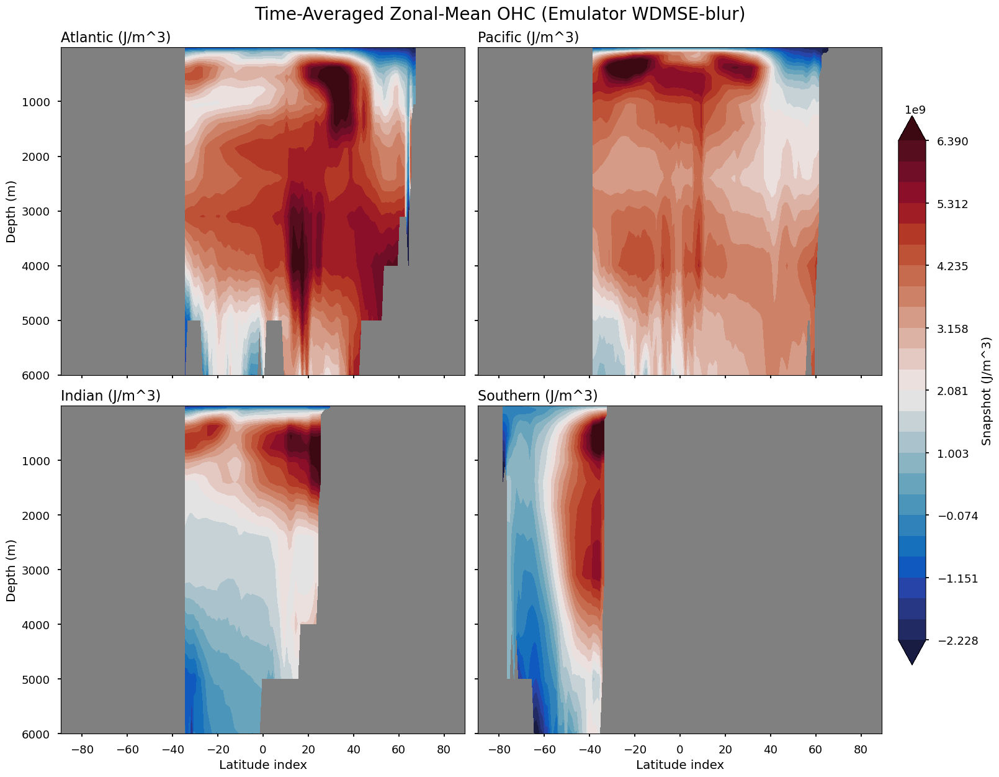

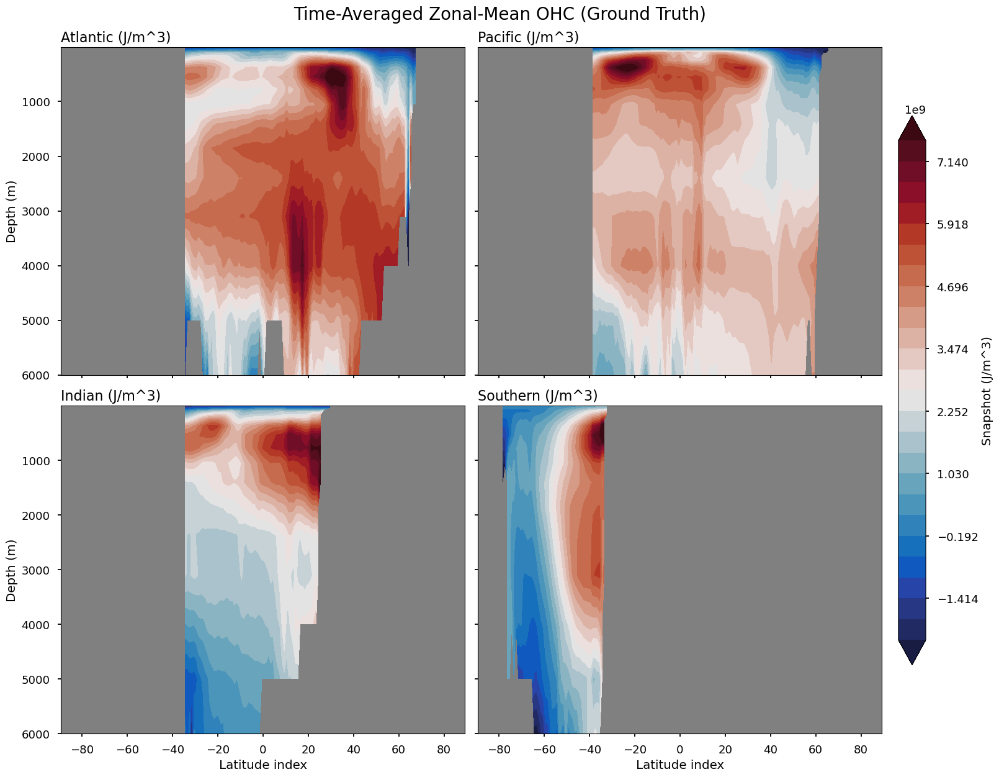

In [15]:
def plot_ohc_zonal_mean_comparison(ds_truth, emulators_dict,variable_name, units, masks):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    variable_name = 'thetao'
    units = 'J/m^3'
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    truth_field_mean = calculate_ohc_2d(ds_truth).mean('time').compute()
    dx_truth = ds_truth['dx']
    # Determine dimensionality for mask
    wet_mask = (ds_truth[variable_name].isel(time=0, drop=True) * 0 + 1).compute()
    
    # 1. Compute Truth Maps (Row 1)
    truth_profiles = {}
    print("Calculating Truth Zonal Profiles...")
    for basin in BASINS_TO_PLOT:
        truth_profiles[basin] = calculate_zonal_mean_2d(
            truth_field_mean, masks[basin], dx_truth, wet_mask
        ).compute()

    # 2. Compute Emulator Maps
    emu_maps = {}
    for label, emu_data in emulators_dict.items():
        print(f"Calculating OHC Maps for {label}...")
        ds_emu = emu_data['ds']
        emu_field_mean = calculate_ohc_2d(ds_emu).mean('time').compute()
        emu_maps[label] = {}

        print(f"\nGenerating Zonal Mean Plot for {label}...")
        
        for basin in BASINS_TO_PLOT:
            # Calculate Emulator Profile using TRUTH metrics
            emu_maps[label][basin] = calculate_zonal_mean_2d(
                emu_field_mean, masks[basin], dx_truth, wet_mask
            ).compute()

        # --- Plotting ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 98)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)
            cmap = cmocean.cm.balance

            ax = axes[i]
            p_mesh = emu_maps[label][basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Time-Averaged Zonal-Mean OHC ({label})", fontsize=20, y=1.03)
        plt.show()

        # --- Plotting ground truth ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 99.5)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)

            ax = axes[i]
            p_mesh = truth_profiles[basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Time-Averaged Zonal-Mean OHC (Ground Truth)", fontsize=20, y=1.03)
        plt.show()

# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)

plot_ohc_zonal_mean_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks
)


Preparing Truth Metrics...
Calculating Truth Zonal Profiles...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Temperature Maps for Emulator WDMSE...

Generating Zonal Bias Plot for Emulator WDMSE...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


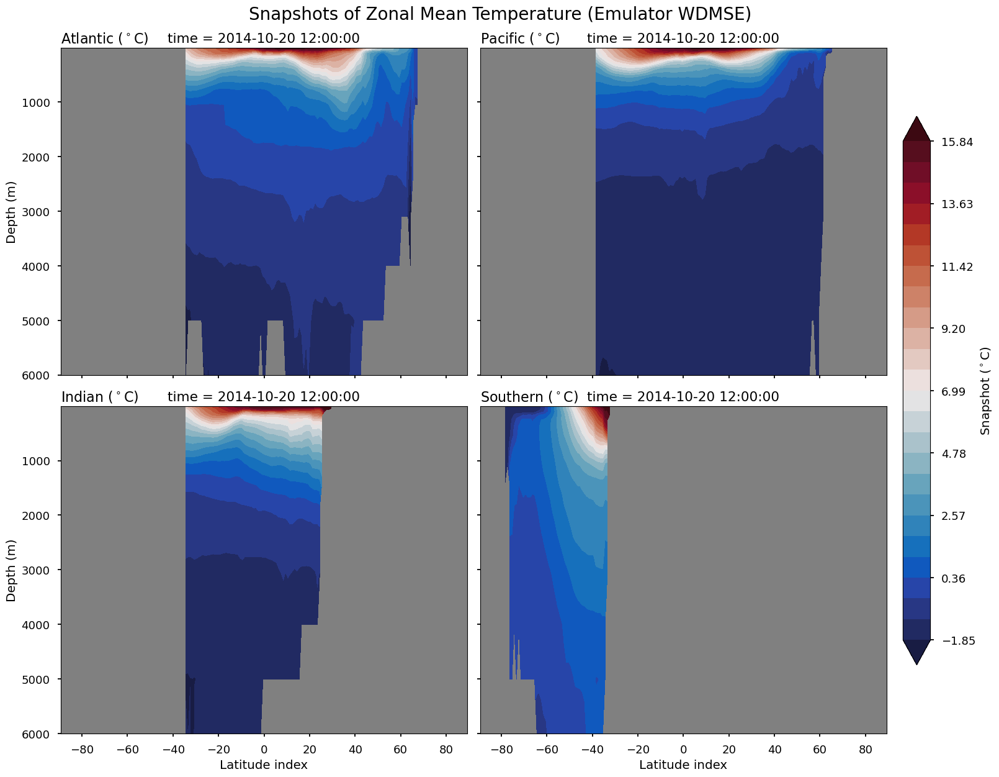

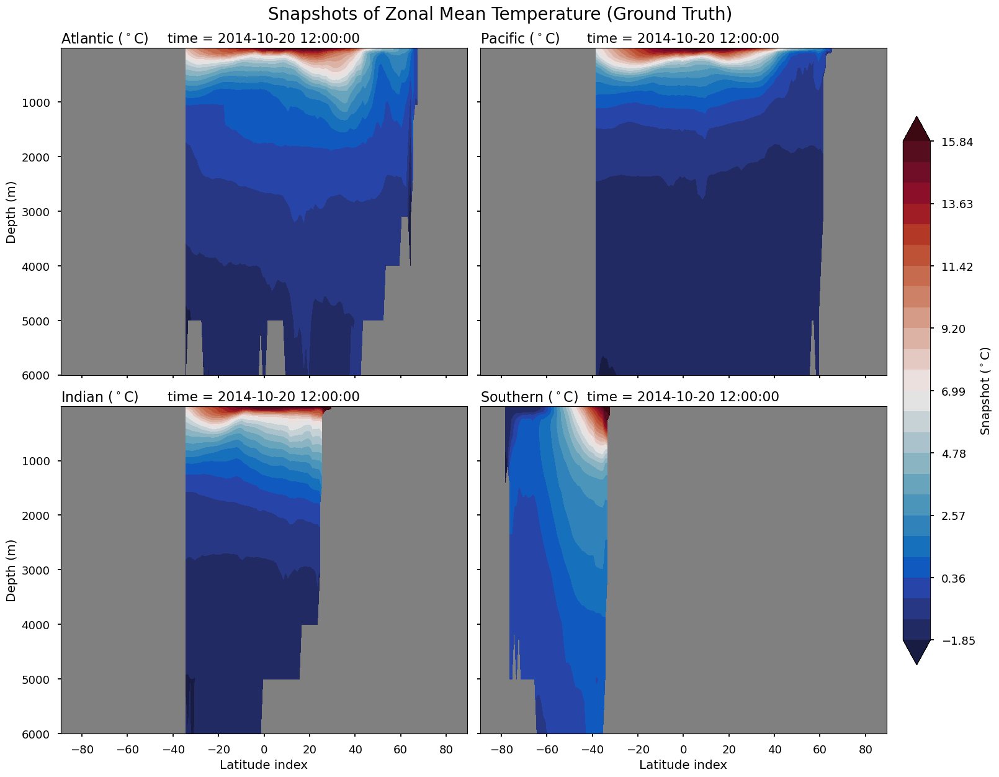

Calculating Temperature Maps for Emulator WDMSE-blur...

Generating Zonal Bias Plot for Emulator WDMSE-blur...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


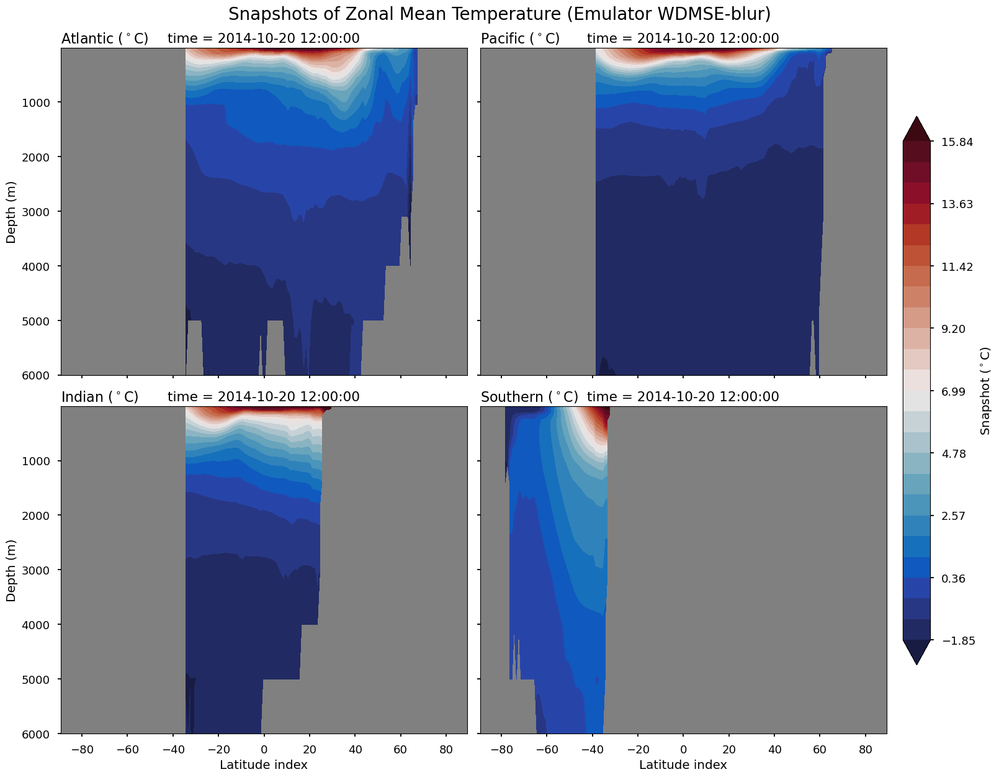

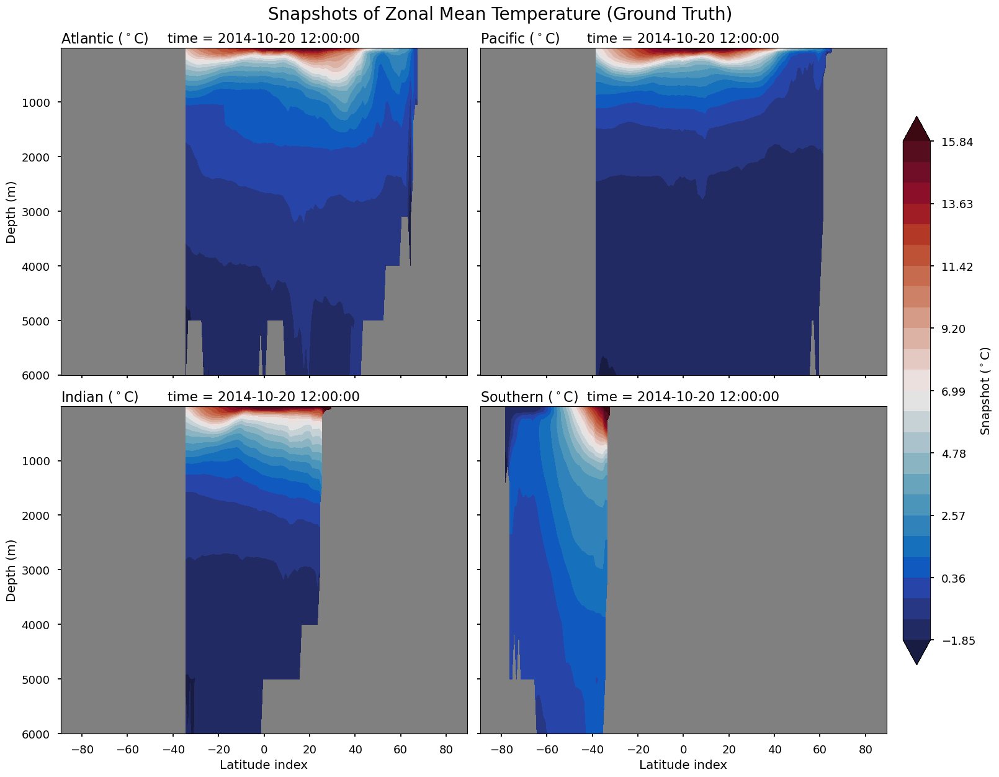

In [16]:
def plot_zonal_snapshot_comparison(ds_truth, emulators_dict,variable_name, units, masks):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    target_step = 0
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    truth_field_mean = ds_truth[variable_name].isel(time=target_step)
    dx_truth = ds_truth['dx']
    # Determine dimensionality for mask
    wet_mask = (ds_truth[variable_name].isel(time=0) * 0 + 1).compute()
    
    # 1. Compute Truth Maps (Row 1)
    truth_profiles = {}
    print("Calculating Truth Zonal Profiles...")
    for basin in BASINS_TO_PLOT:
        truth_profiles[basin] = calculate_zonal_mean(
            truth_field_mean, masks[basin], dx_truth, wet_mask
        ).compute()

    # 2. Compute Emulator Maps
    emu_maps = {}
    for label, emu_data in emulators_dict.items():
        print(f"Calculating Temperature Maps for {label}...")
        ds_emu = emu_data['ds']
        emu_field_mean = ds_emu[variable_name].isel(time=target_step)
        emu_maps[label] = {}

        print(f"\nGenerating Zonal Bias Plot for {label}...")
        
        # Weights for RMSE (Mean across X)
        weight_2d = (ds_truth['dy'] * ds_truth['dz']).mean('x').compute()

        for basin in BASINS_TO_PLOT:
            # Calculate Emulator Profile using TRUTH metrics
            emu_maps[label][basin] = calculate_zonal_mean(
                emu_field_mean, masks[basin], dx_truth, wet_mask
            ).compute()

        # --- Plotting ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 98)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)
            cmap = cmocean.cm.balance

            ax = axes[i]
            p_mesh = emu_maps[label][basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Snapshots of Zonal Mean Temperature ({label})", fontsize=20, y=1.03)
        plt.show()

        # --- Plotting ground truth ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 98)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)

            ax = axes[i]
            p_mesh = truth_profiles[basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Snapshots of Zonal Mean Temperature (Ground Truth)", fontsize=20, y=1.03)
        plt.show()

# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)

plot_zonal_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks
)


Preparing Truth Metrics...
Calculating Truth Zonal Profiles...
Calculating OHC Maps for Emulator WDMSE...

Generating Zonal Mean Plot for Emulator WDMSE...


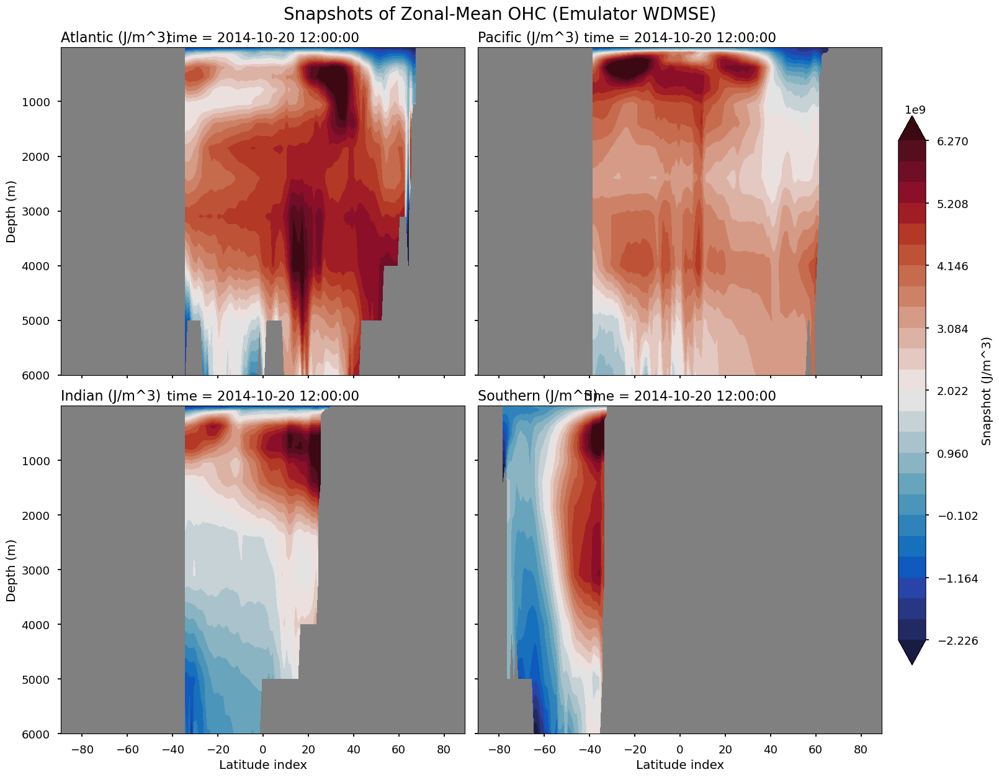

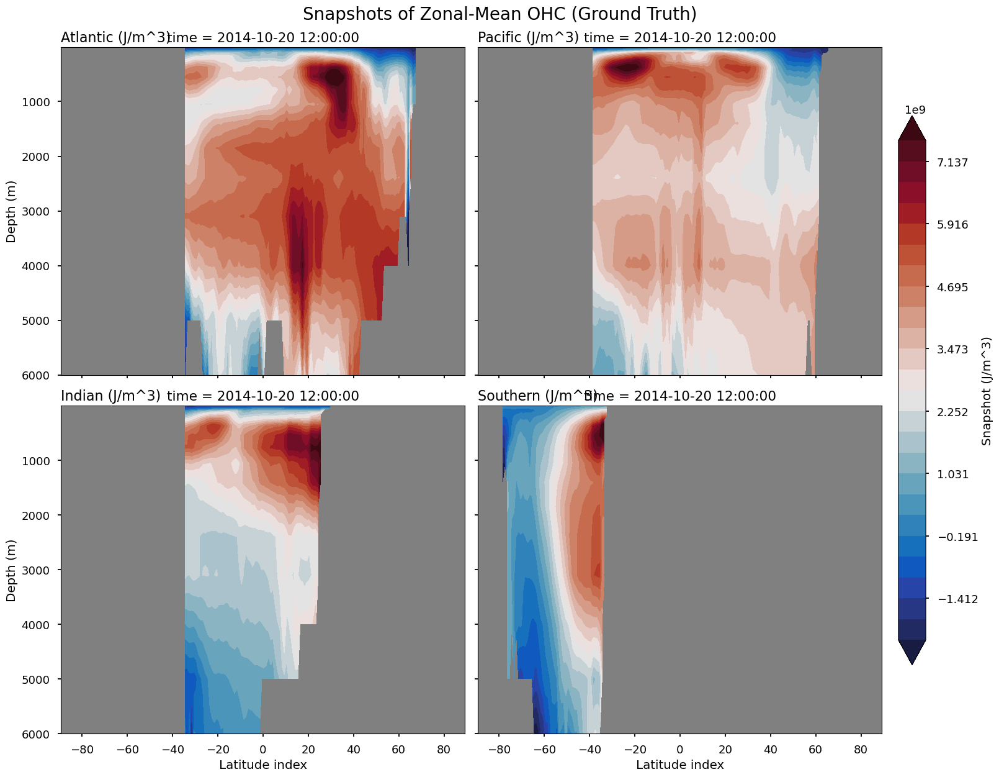

Calculating OHC Maps for Emulator WDMSE-blur...

Generating Zonal Mean Plot for Emulator WDMSE-blur...


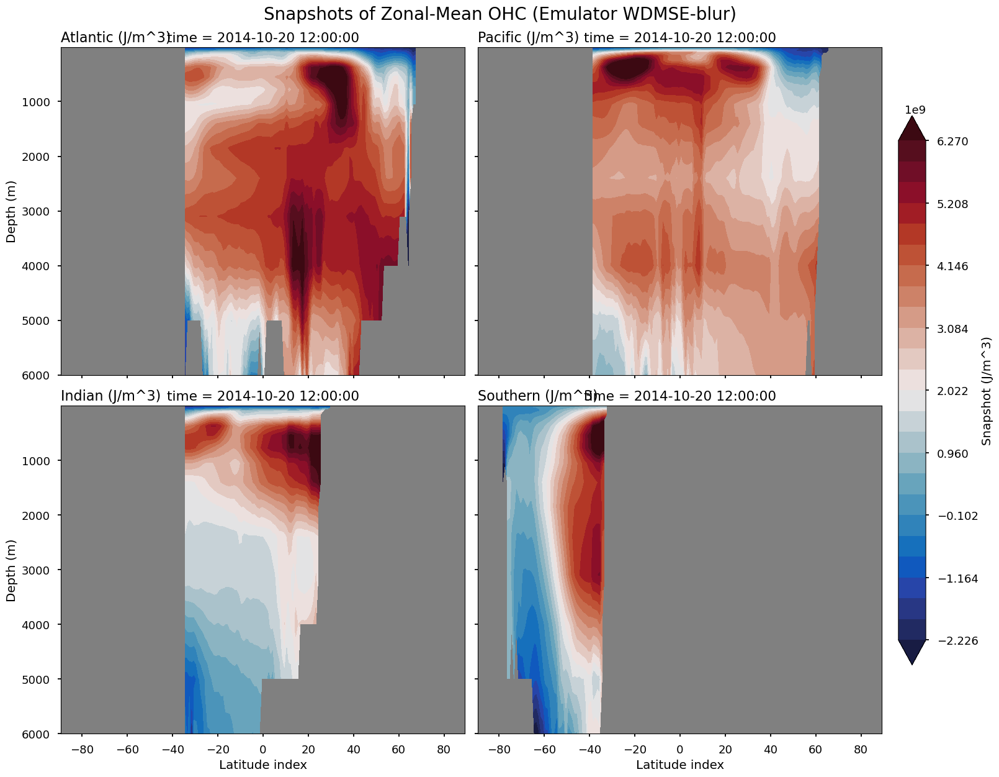

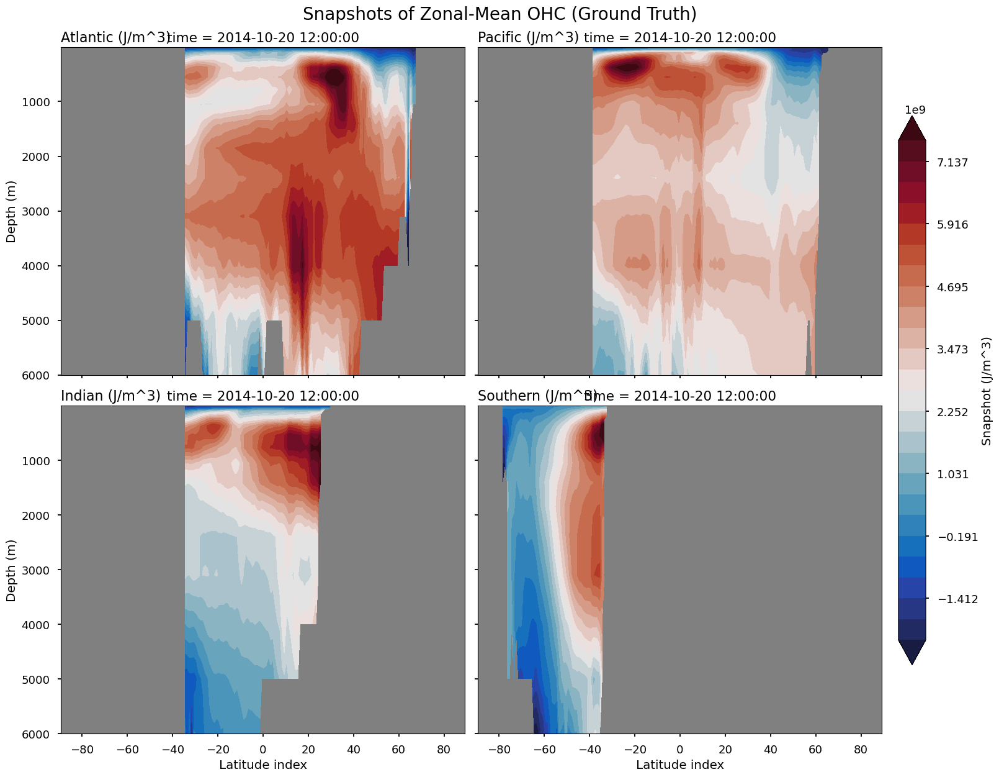

In [17]:
def plot_ohc_zonal_snapshot_comparison(ds_truth, emulators_dict,variable_name, units, masks):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    variable_name = 'thetao'
    units = 'J/m^3'
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    target_step = 0
    truth_field_mean = calculate_ohc_2d(ds_truth).isel(time=target_step).compute()
    dx_truth = ds_truth['dx']
    # Determine dimensionality for mask
    wet_mask = (ds_truth[variable_name].isel(time=0) * 0 + 1).compute()
    
    # 1. Compute Truth Maps (Row 1)
    truth_profiles = {}
    print("Calculating Truth Zonal Profiles...")
    for basin in BASINS_TO_PLOT:
        truth_profiles[basin] = calculate_zonal_mean_2d(
            truth_field_mean, masks[basin], dx_truth, wet_mask
        ).compute()

    # 2. Compute Emulator Maps
    emu_maps = {}
    for label, emu_data in emulators_dict.items():
        print(f"Calculating OHC Maps for {label}...")
        ds_emu = emu_data['ds']
        emu_field_mean = calculate_ohc_2d(ds_emu).isel(time=target_step).compute()
        emu_maps[label] = {}

        print(f"\nGenerating Zonal Mean Plot for {label}...")
        
        for basin in BASINS_TO_PLOT:
            # Calculate Emulator Profile using TRUTH metrics
            emu_maps[label][basin] = calculate_zonal_mean_2d(
                emu_field_mean, masks[basin], dx_truth, wet_mask
            ).compute()

        # --- Plotting ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 98)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)
            cmap = cmocean.cm.balance

            ax = axes[i]
            p_mesh = emu_maps[label][basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Snapshots of Zonal-Mean OHC ({label})", fontsize=20, y=1.03)
        plt.show()

        # --- Plotting ground truth ---
        plt.style.use('seaborn-v0_8-talk')
        fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)
        axes = axes.flatten()

        for i, basin in enumerate(BASINS_TO_PLOT):
            data_truth = truth_profiles[basin].values
            valid_data = data_truth[~np.isnan(data_truth)]
            
            vmin = np.percentile(valid_data, .5)
            vmax = np.percentile(valid_data, 99.5)
            norm = colors.Normalize(vmin=vmin, vmax=vmax)

            ax = axes[i]
            p_mesh = truth_profiles[basin].plot.contourf(
                ax=ax, cmap=cmap, norm=norm, add_colorbar=False, 
                levels=np.linspace(vmin, vmax, 25), yincrease=False,
                x='y', y='lev' 
            )
            ax.set_title(f"{basin} ({units})", fontsize=16, loc='left')
            ax.set_facecolor('grey')
            ax.set_xlabel(''); ax.set_ylabel('')
        
        axes[0].set_ylabel('Depth (m)'); axes[2].set_ylabel('Depth (m)')
        axes[2].set_xlabel('Latitude index'); axes[3].set_xlabel('Latitude index')
        cbar = fig.colorbar(p_mesh, ax=axes, shrink=0.8, pad=0.02)
        cbar.set_label(f"Snapshot ({units})")
        fig.suptitle(f"Snapshots of Zonal-Mean OHC (Ground Truth)", fontsize=20, y=1.03)
        plt.show()

# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)

plot_ohc_zonal_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks
)


Preparing Truth Metrics...
Calculating Truth OHC Maps...
Calculating OHC Maps for Emulator WDMSE...
  > Bias Range (98th percentile): +/- 0.029 ZJ
local_max:  0.02908006984169501
  > Upper Ocean (0-700m) Scale locked to: +/- 2.908e-02 ZJ
local_max:  0.020797262375614564
  > Mid-Ocean (700-2000m) Scale locked to: +/- 2.080e-02 ZJ
local_max:  0.009083263611350888
  > Deep Ocean (2000m+) Scale locked to: +/- 9.083e-03 ZJ
local_max:  0.03936215932928253
  > Full Ocean Scale locked to: +/- 3.936e-02 ZJ


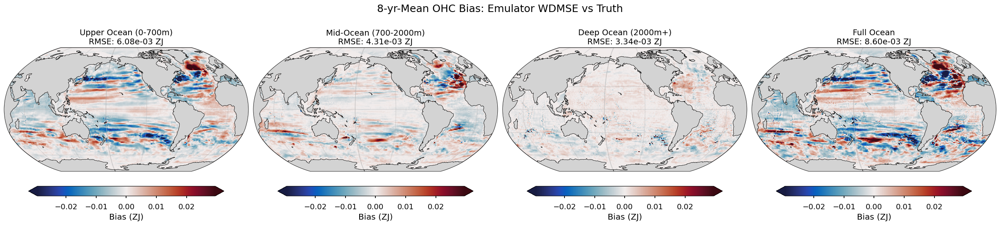

Calculating OHC Maps for Emulator WDMSE-blur...
  > Bias Range (98th percentile): +/- 0.031 ZJ


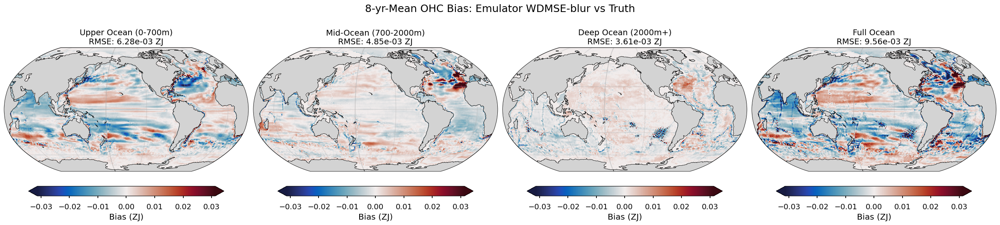

In [18]:
# --------------------------------------------------------------------------------
# BLOCK 12: Mean Ocean Heat Content (OHC) bias Maps Comparison
# --------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature


units = 'ZJ'

def plot_ohc_bias_comparison(ds_truth, emulators_dict):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    dz_truth = ds_truth['dz']
    # Wet mask from Truth (1 for Ocean, NaN for Land)
    wet_mask = (ds_truth['thetao'].isel(time=0) * 0 + 1).compute()
    area = ds_truth['areacello']
    
    # 1. Compute Truth Maps (Row 1)
    truth_maps = {}
    print("Calculating Truth OHC Maps...")
    for Slices in DEPTH_SLICES:
        key = Slices['title']
        truth_maps[key] = calculate_ohc_map(
            ds_truth, dz_truth, wet_mask, Slices['min'], Slices['max']
        ).compute()
        
    # 2. Compute Emulator Maps
    emu_maps = {}
    shared_limits = {}
    for idx, (label, emu_data) in enumerate(emulators_dict.items()):
        print(f"Calculating OHC Maps for {label}...")
        ds_emu = emu_data['ds']
        emu_maps[label] = {}
        bias_maps = {}
        rmse_vals = {}
        all_biases_flat = []

        for Slices in DEPTH_SLICES:
            key = Slices['title']
            # Note: We use Truth's dz and wet_mask to ensure integration domain consistency
            emu_maps[label][key] = calculate_ohc_map(
                ds_emu, dz_truth, wet_mask, Slices['min'], Slices['max']
            ).compute()

            map_truth = truth_maps[key]
            map_emu = emu_maps[label][key]

            bias = map_emu - map_truth
            bias_maps[key] = bias

            rmse_vals[key] = rmse_spatial(map_truth, map_emu, area)    

            all_biases_flat.append(bias.values.flatten())

        # Dynamic Color Scaling
        flat_data = np.concatenate(all_biases_flat)
        flat_data = flat_data[~np.isnan(flat_data)]
        
        if len(flat_data) > 0:
            max_abs_bias = np.percentile(np.abs(flat_data), 99.5)
            print(f"  > Bias Range (98th percentile): +/- {max_abs_bias:.3f} {units}")
        else:
            max_abs_bias = 1.0

        vmin, vmax = -max_abs_bias, max_abs_bias
        #vmin, vmax = -0.6, 0.6
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        cmap = cmocean.cm.balance

        # --- Plotting Setup ---
        num_slices = len(DEPTH_SLICES)
        
        fig, axes = plt.subplots(
            1, num_slices, 
            figsize=(6 * num_slices, 5),
            subplot_kw={'projection': ccrs.Robinson(central_longitude=210)},
            constrained_layout=True
        )
        
        # Ensure axes is 2D array even if 1 row
        if num_slices == 1: axes = [axes]

        cmap = cmocean.cm.balance

        for i, Slices in enumerate(DEPTH_SLICES):
            key = Slices['title']
            ax = axes[i]
            bias = bias_maps[key]
        
            # Determine Color Scaling (Lock to First Emulator)
            if idx == 0:
                flat_bias = bias.values.flatten()
                flat_bias = flat_bias[~np.isnan(flat_bias)]
                
                if len(flat_bias) > 0:
                    local_max = np.percentile(np.abs(flat_bias), 99.5)
                else:
                    local_max = 1.0

                print('local_max: ', local_max)
                
                shared_limits[key] = local_max
                print(f"  > {key} Scale locked to: +/- {local_max:.3e} {units}")
            
            limit = shared_limits[key]
            #norm = colors.Normalize(vmin=-limit, vmax=limit)
            
            # Plot with INDIVIDUAL colorbar
            p = bias.plot.pcolormesh(
                ax=ax, transform=ccrs.PlateCarree(),
                x='x', y='y',
                cmap=cmap, norm=norm, 
                add_colorbar=True,
                cbar_kwargs={
                    'orientation': 'horizontal', 
                    'shrink': 0.8, 
                    'pad': 0.08, 
                    'label': f"Bias ({units})"
                },
                rasterized=True
            )
            
            ax.set_title(f"{key}\nRMSE: {rmse_vals[key]:.2e} {units}" + r"", fontsize=14)
            ax.add_feature(cfeature.LAND, zorder=10, edgecolor='black', facecolor='lightgray')
            ax.coastlines(zorder=11)
            ax.gridlines(draw_labels=False, alpha=0.3)

        fig.suptitle(f"8-yr-Mean OHC Bias: {label} vs Truth", fontsize=18, y=1.05)
        plt.show()

# --- Execution ---
plot_ohc_bias_comparison(dataset_truth, emulators_to_analyze)


Preparing Truth Metrics...
Calculating Truth Temperature Maps...
Calculating Temperature Maps for Emulator WDMSE...
  > Bias Range (98th percentile): +/- 1.113 $^\circ$C
  > 2.5m Scale locked to: +/- 1.606e+00 $^\circ$C
  > 700m Scale locked to: +/- 9.616e-01 $^\circ$C
  > 2000m Scale locked to: +/- 2.183e-01 $^\circ$C
  > 3000m Scale locked to: +/- 1.212e-01 $^\circ$C
Calculating Temperature Maps for Emulator WDMSE-blur...
  > Bias Range (98th percentile): +/- 0.768 $^\circ$C


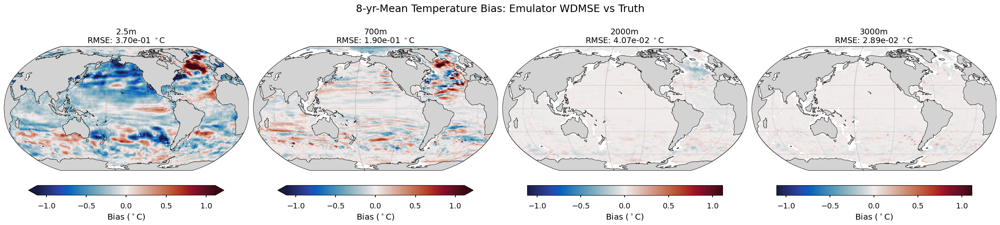

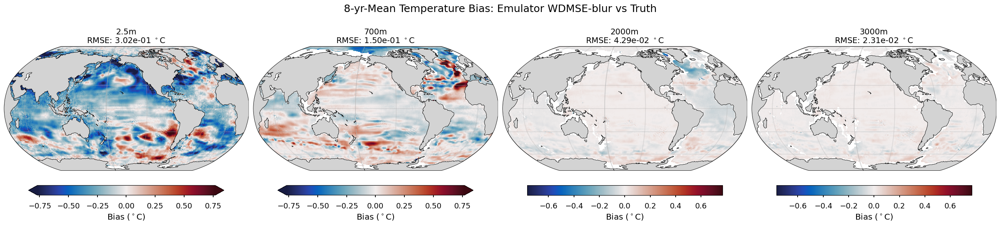

In [20]:
# --------------------------------------------------------------------------------
# BLOCK 12: Mean temperature Maps Comparison
# --------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Configuration ---
VARIABLE_TO_PLOT = 'thetao'  # Options: 'thetao', 'so', 'zos', 'uo', 'vo'
units = '$^\circ$C'

def plot_temperature_bias_comparison(ds_truth, ds_truth_blur, emulators_dict):
    """
    Generates a grid of OHC maps:
    Rows: Datasets (Truth, Emulator 1, Emulator 2...)
    Cols: Depth Slices (Upper, Mid, Deep)
    """
    
    # Setup Metrics
    print("Preparing Truth Metrics...")
    dz_truth = ds_truth['dz']
    dz_truth_blur = ds_truth_blur['dz']
    # Determine dimensionality for mask
    if 'lev' in ds_truth[VARIABLE_TO_PLOT].dims:
        wet_mask = (ds_truth[VARIABLE_TO_PLOT].isel(time=0) * 0 + 1).compute()
    else:
        # For 2D vars like zos, check for 2D or 3D mask availability
        # Fallback to simple NaN check on the 2D variable itself
        wet_mask = (ds_truth[VARIABLE_TO_PLOT].isel(time=0) * 0 + 1).compute()

    # 1. Compute Truth Maps (Row 1)
    truth_maps = {}
    truth_blur_maps = {}
    area = ds_truth['areacello']
    print("Calculating Truth Temperature Maps...")
    for Slices in DEPTH_LAYERS:
        key = Slices['title']
        truth_maps[key] = calculate_temperature_map_layer(
            ds_truth, VARIABLE_TO_PLOT, dz_truth, wet_mask, Slices['index']
        ).compute()
        truth_blur_maps[key] = calculate_temperature_map_layer(
            ds_truth_blur, VARIABLE_TO_PLOT, dz_truth_blur, wet_mask, Slices['index']
        ).compute()
    # 2. Compute Emulator Maps
    emu_maps = {}
    shared_limits = {}
    for idx, (label, emu_data) in enumerate(emulators_dict.items()):
        print(f"Calculating Temperature Maps for {label}...")
        bias_maps = {}
        rmse_vals = {}
        all_biases_flat  = []
        ds_emu = emu_data['ds']
        emu_maps[label] = {}
        for Slices in DEPTH_LAYERS:
            key = Slices['title']
            # Note: We use Truth's dz and wet_mask to ensure integration domain consistency
            emu_maps[label][key] = calculate_temperature_map_layer(
                ds_emu, VARIABLE_TO_PLOT,  dz_truth, wet_mask, Slices['index']
            ).compute()
            
            if label == EMULATOR_1_LABEL:
                map_truth = truth_maps[key]
            if label == EMULATOR_2_LABEL:
                map_truth = truth_blur_maps[key]
            
            map_emu = emu_maps[label][key]

            bias_maps[key] = map_emu - map_truth 
            rmse_vals[key] = rmse_spatial(map_emu, map_truth, area)

            all_biases_flat.append(bias_maps[key].values.flatten())

        # Dynamic Color Scaling
        flat_data = np.concatenate(all_biases_flat)
        flat_data = flat_data[~np.isnan(flat_data)]
        
        if len(flat_data) > 0:
            max_abs_bias = np.percentile(np.abs(flat_data), 99.5)
            print(f"  > Bias Range (98th percentile): +/- {max_abs_bias:.3f} {units}")
        else:
            max_abs_bias = 1.0

        vmin, vmax = -max_abs_bias, max_abs_bias
        #vmin, vmax = -0.6, 0.6
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        cmap = cmocean.cm.balance


        # --- Plotting ---
        num_slices = len(DEPTH_SLICES)
        fig, axes = plt.subplots(
            1, num_slices, 
            figsize=(6 * num_slices, 5),
            subplot_kw={'projection': ccrs.Robinson(central_longitude=210)},
            constrained_layout=True
        )
        if num_slices == 1: axes = [axes]
        
        cmap = cmocean.cm.balance
        
        for i, Slices in enumerate(DEPTH_LAYERS):
            key = Slices['title']
            ax = axes[i]
            bias = bias_maps[key]
            
            # Determine Color Scaling (Lock to First Emulator)
            if idx == 0:
                flat_bias = bias.values.flatten()
                flat_bias = flat_bias[~np.isnan(flat_bias)]
                
                if len(flat_bias) > 0:
                    local_max = np.percentile(np.abs(flat_bias), 99.5)
                else:
                    local_max = 1.0
                
                shared_limits[key] = local_max
                print(f"  > {key} Scale locked to: +/- {local_max:.3e} {units}")
            
            limit = shared_limits[key]
            #norm = colors.Normalize(vmin=-limit, vmax=limit)
            
            # Plot with INDIVIDUAL colorbar
            p = bias.plot.pcolormesh(
                ax=ax, transform=ccrs.PlateCarree(),
                x='x', y='y',
                cmap=cmap, norm=norm, 
                add_colorbar=True,
                cbar_kwargs={
                    'orientation': 'horizontal', 
                    'shrink': 0.8, 
                    'pad': 0.08, 
                    'label': f"Bias ({units})"
                },
                rasterized=True
            )
            
            ax.set_title(f"{key}\nRMSE: {rmse_vals[key]:.2e} {units}" + r"", fontsize=14)
            ax.add_feature(cfeature.LAND, zorder=10, edgecolor='black', facecolor='lightgray')
            ax.coastlines(zorder=11)
            ax.gridlines(draw_labels=False, alpha=0.3)
        
        fig.suptitle(f"8-yr-Mean Temperature Bias: {label} vs Truth", fontsize=18, y=1.05)
    plt.show()

# --- Execution ---
plot_temperature_bias_comparison(dataset_truth, dataset_truth_blur, emulators_to_analyze)

Preparing Snapshot Maps for Temperature (2.5m)...


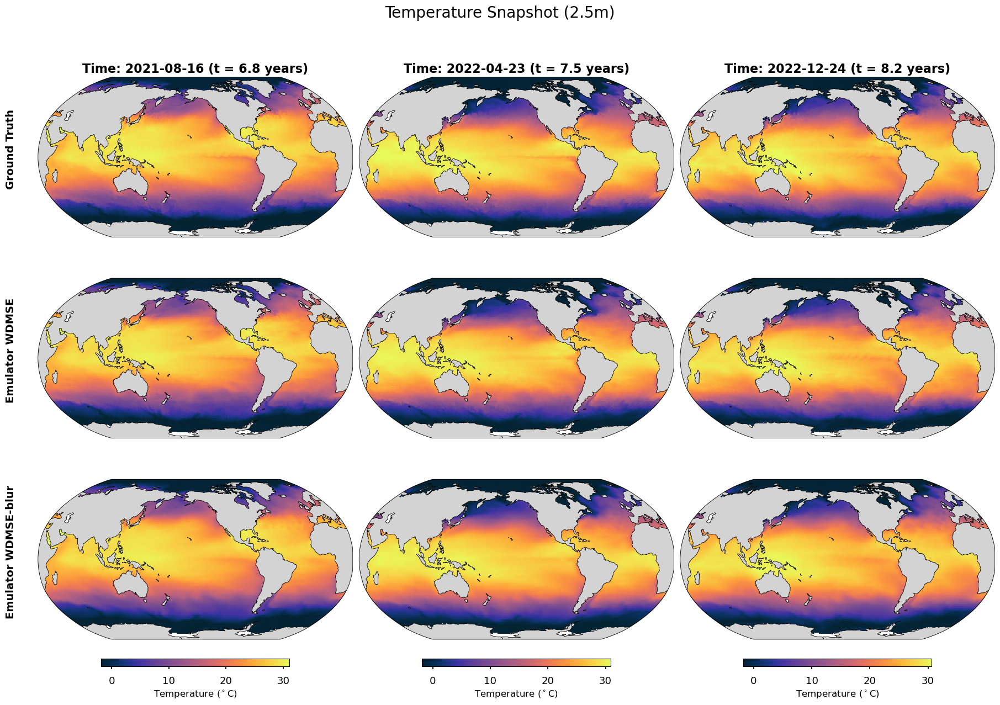

Preparing Snapshot Maps for Temperature (700m)...


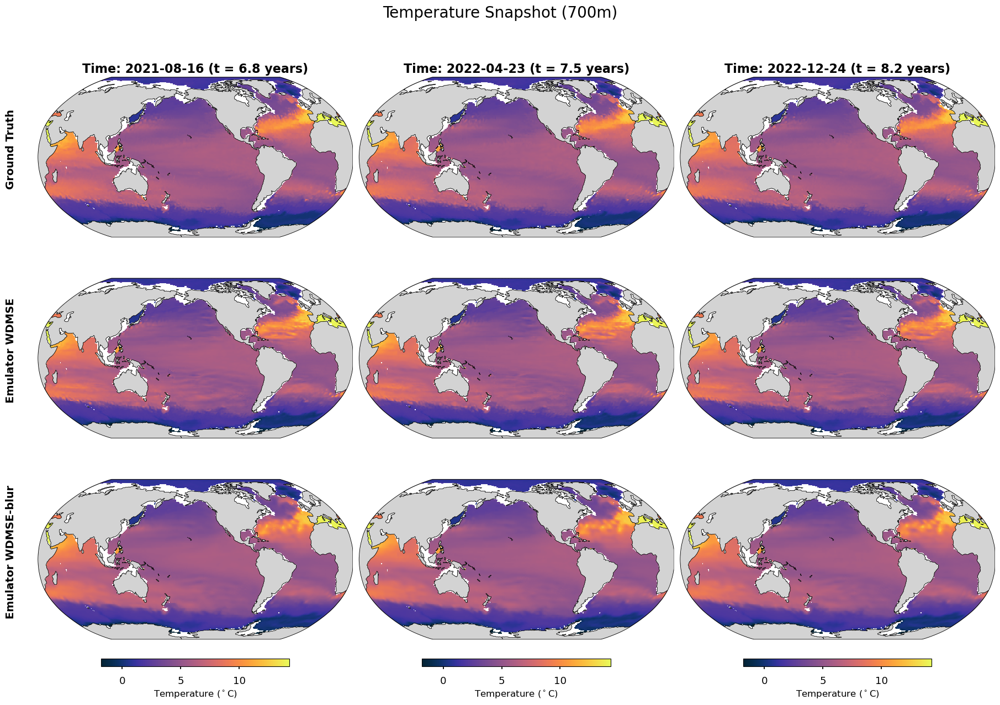

Preparing Snapshot Maps for Temperature (2000m)...


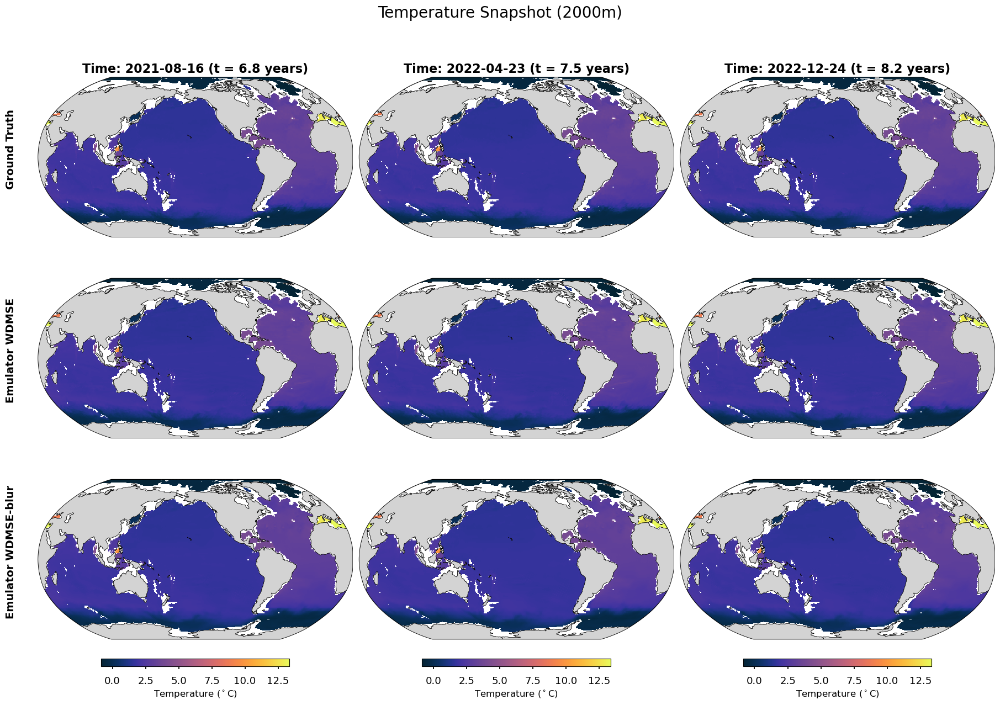

Preparing Snapshot Maps for Temperature (3000m)...


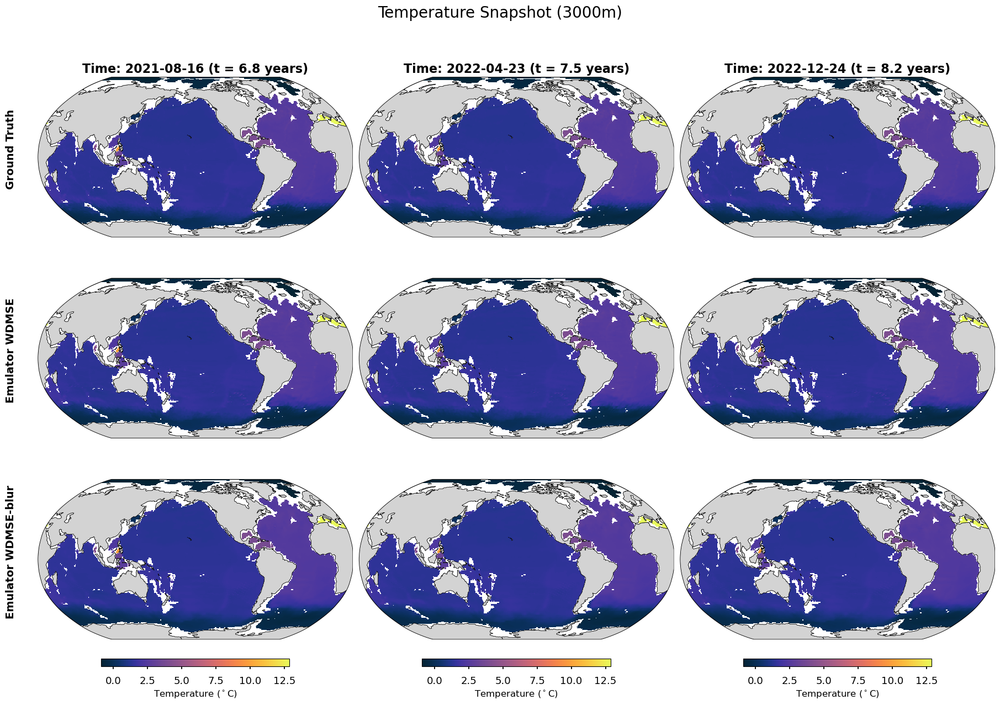

In [21]:
# --------------------------------------------------------------------------------
# BLOCK 14: Snapshots of Depth-Averaged Variables
# --------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Configuration ---
VARIABLE_TO_PLOT = 'thetao'  # Options: 'thetao', 'so', 'zos', 'uo', 'vo'
TIME_INDICES = [-100, -50, -1]   # Index of time steps to plot (e.g. Initial, Short, Long)



def calculate_snapshot_map(dataset, var_name, dz, wet_mask, depth_index, time_idx):
    """
    Computes a 2D map for a specific variable at a specific time index.
    - 3D vars: Computes depth-weighted average.
    - 2D vars: Returns surface field masked by Truth.
    """
    # Select Time Step
    ds_t = dataset.isel(time=time_idx)
    field = ds_t[var_name]
    
    # Select Depth Slice
    f_slice = field.isel(lev=depth_index)
    dz_slice = dz.isel(lev=depth_index)
    wet_slice = wet_mask.isel(lev=depth_index)
    
    # Depth Average
    numerator = (f_slice * dz_slice * wet_slice)
    denominator = (dz_slice * wet_slice)
    result = numerator / denominator
        
    return result.compute()

def plot_snapshot_comparison(ds_truth, emulators_dict, var_name, time_indices, depth_config):
    """
    Generates a grid of snapshot maps:
    Rows: Datasets
    Cols: Time Indices
    """
    config = VAR_CONFIG.get(var_name, {'cmap': 'viridis', 'units': '', 'label': var_name, 'centered': False})
    units = config['units']
    
    print(f"Preparing Snapshot Maps for {config['label']} ({depth_config['title']})...")
    
    # Setup Metrics from Truth
    dz_truth = ds_truth['dz']
    
    # Determine dimensionality for mask
    if 'lev' in ds_truth[var_name].dims:
        wet_mask = (ds_truth[var_name].isel(time=0) * 0 + 1).compute()
    else:
        # For 2D vars like zos, check for 2D or 3D mask availability
        # Fallback to simple NaN check on the 2D variable itself
        wet_mask = (ds_truth[var_name].isel(time=0) * 0 + 1).compute()

    # Pre-Compute Maps
    # Structure: maps[dataset_label][time_index]
    maps_data = {}
    datasets = [TRUTH_LABEL] + list(emulators_dict.keys())
    
    # 1. Truth
    maps_data[TRUTH_LABEL] = {}
    for t in time_indices:
        maps_data[TRUTH_LABEL][t] = calculate_snapshot_map(
            ds_truth, var_name, dz_truth, wet_mask, 
            depth_config['index'], t
        )
        
    # 2. Emulators
    for label, emu_data in emulators_dict.items():
        ds_emu = emu_data['ds']
        maps_data[label] = {}
        for t in time_indices:
            # Note: Using Truth's dz and wet_mask for consistency
            maps_data[label][t] = calculate_snapshot_map(
                ds_emu, var_name, dz_truth, wet_mask, 
                depth_config['index'], t
            )

    # --- Plotting ---
    nrows = len(datasets)
    ncols = len(time_indices)
    
    fig, axes = plt.subplots(
        nrows, ncols, 
        figsize=(6 * ncols, 4 * nrows),
        subplot_kw={'projection': ccrs.Robinson(central_longitude=210)},
        constrained_layout=True
    )
    
    if nrows == 1: axes = np.expand_dims(axes, 0)
    if ncols == 1: axes = np.expand_dims(axes, 1)

    cmap = config['cmap']
    
    # Iterate Column-by-Column (Time Steps) to lock colorbars
    for j, t_idx in enumerate(time_indices):
        
        # Determine Range based on TRUTH at this timestep
        truth_slice = maps_data[TRUTH_LABEL][t_idx].values
        valid_data = truth_slice[~np.isnan(truth_slice)]
        
        if len(valid_data) > 0:
            if config['centered']:
                # Centered Colorbar (e.g. Velocity, SSH anomaly)
                abs_max = np.percentile(np.abs(valid_data), 99.75)
                vmin, vmax = -abs_max, abs_max
            else:
                # Sequential Colorbar (e.g. Temperature)
                vmin = np.percentile(valid_data, .25)
                vmax = np.percentile(valid_data, 99.75)
        else:
            vmin, vmax = 0, 1
            
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        
        # Retrieve actual time string for title
        try:
            time_val = ds_truth.time[t_idx].values
            # Format nicely if it's datetime/cftime
            if hasattr(time_val, 'strftime'):
                time_str = time_val.strftime("%Y-%m-%d")
            else:
                time_str = str(time_val)[:10]
        except:
            time_str = f"Index {t_idx}"


        try:
            # Extract raw values to handle both numpy and cftime objects
            t0_val = ds_truth.time.values[0]
            ti_val = ds_truth.time.values[t_idx]
            
            delta = ti_val - t0_val
            
            # Convert to days
            if isinstance(delta, np.timedelta64):
                # Convert from nanoseconds (default for xarray/numpy) to days
                days_elapsed = float(delta) / (1e9 * 86400)
            else:
                # Assume datetime.timedelta (cftime)
                days_elapsed = delta.days + delta.seconds / 86400.0
            
            if days_elapsed < 365:
                day_str = f"t = {int(days_elapsed)} days"
            else:
                years = days_elapsed / 365
                day_str = f"t = {years:.1f} years"
        except:
            day_str = f"Index {t_idx}"

        
        # Iterate Row-by-Row (Datasets)
        for i, ds_name in enumerate(datasets):
            ax = axes[i, j]
            data_to_plot = maps_data[ds_name][t_idx]
            
            p = data_to_plot.plot.pcolormesh(
                ax=ax, transform=ccrs.PlateCarree(),
                x='x', y='y',
                cmap=cmap, norm=norm,
                add_colorbar=False,
                rasterized=True
            )
            
            ax.add_feature(cfeature.LAND, zorder=10, edgecolor='black', facecolor='lightgray')
            ax.coastlines(zorder=11)
            
            # Titles
            if i == 0:
                ax.set_title(f"Time: {time_str} ({day_str})", fontsize=16, fontweight='bold')
            else:
                ax.set_title("")
                
            # Row Labels
            if j == 0:
                label_text = "Ground Truth" if ds_name == TRUTH_LABEL else ds_name
                ax.text(-0.07, 0.55, label_text, va='center', ha='right',
                        rotation='vertical', transform=ax.transAxes, 
                        fontsize=14, fontweight='bold')

        # Add Colorbar for this Time Step
        cbar = fig.colorbar(
            p, ax=axes[:, j], 
            orientation='horizontal', 
            shrink=0.6, pad=0.03, aspect=25
        )
        cbar.set_label(f"{config['label']} ({units})", fontsize=12)

    main_title = f"{config['label']} Snapshot"
    if 'lev' in ds_truth[var_name].dims:
        main_title += f" ({depth_config['title']})"
        
    fig.suptitle(main_title, fontsize=20, y=1.05)
    plt.show()

# --- Execution ---
plot_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[0]
)
plot_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[1]
)
plot_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[2]
)

plot_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[3]
)

Preparing Snapshot Maps for OHC (Upper Ocean (0-700m))...


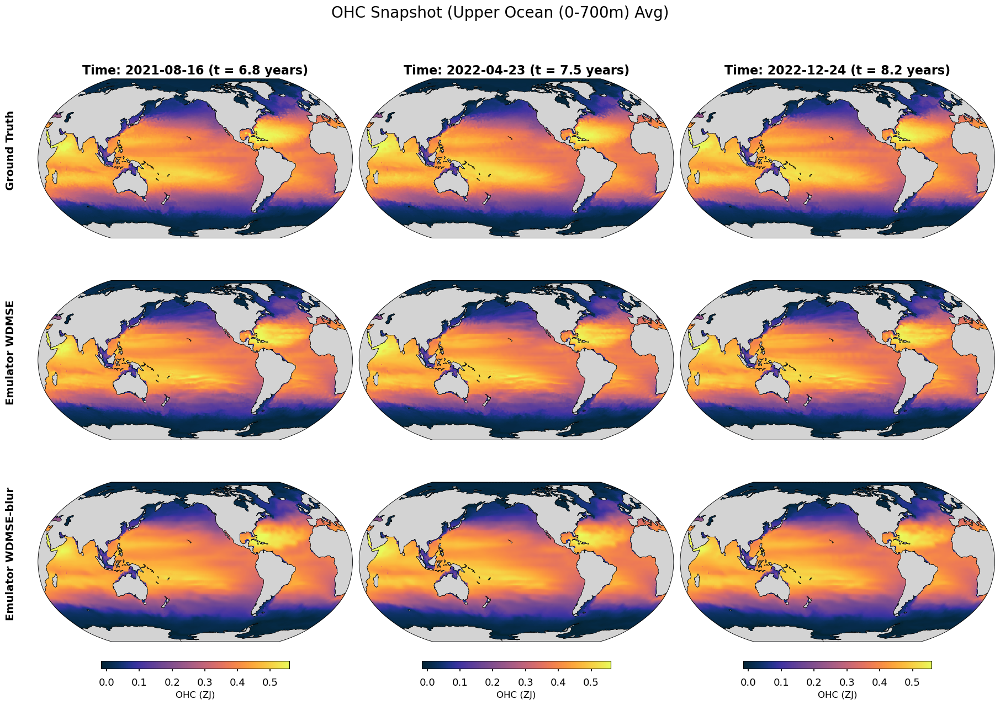

Preparing Snapshot Maps for OHC (Mid-Ocean (700-2000m))...


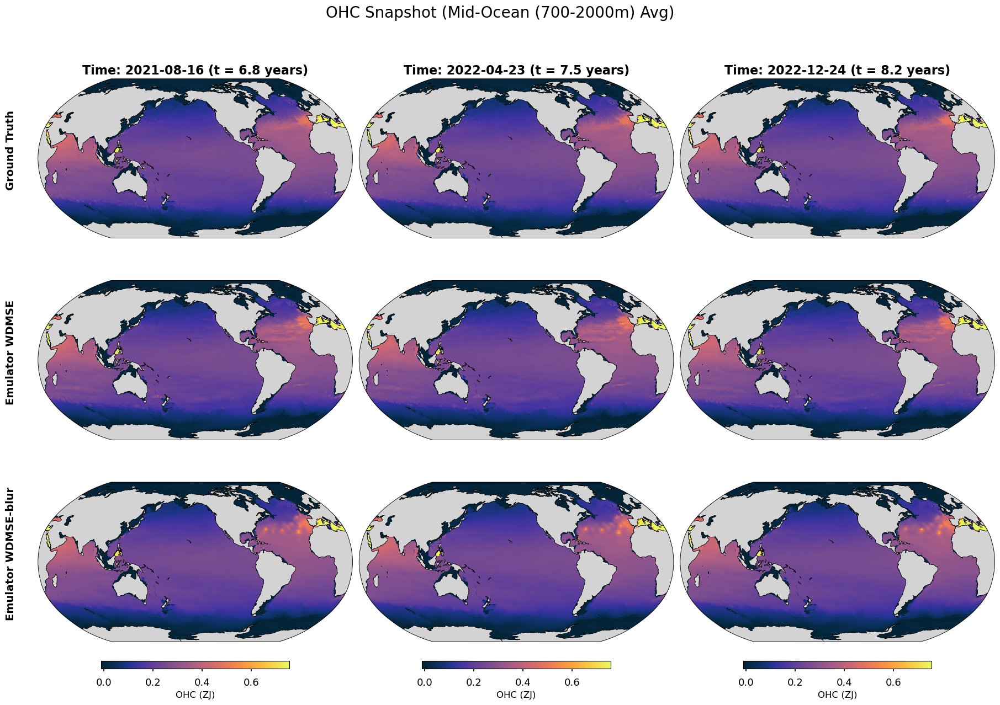

Preparing Snapshot Maps for OHC (Deep Ocean (2000m+))...


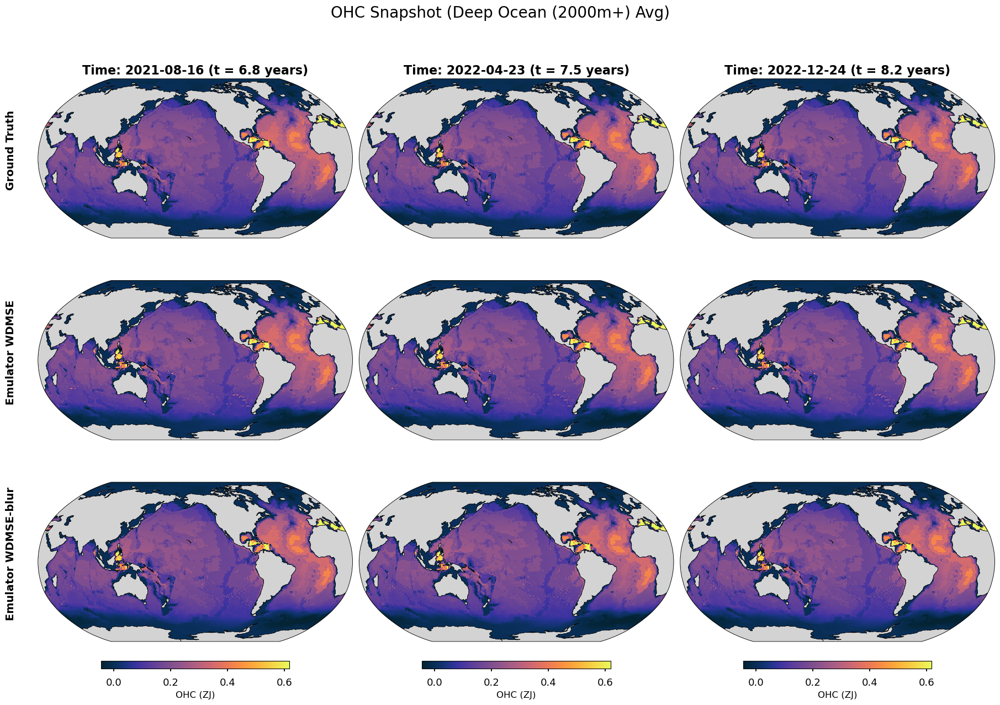

Preparing Snapshot Maps for OHC (Full Ocean)...


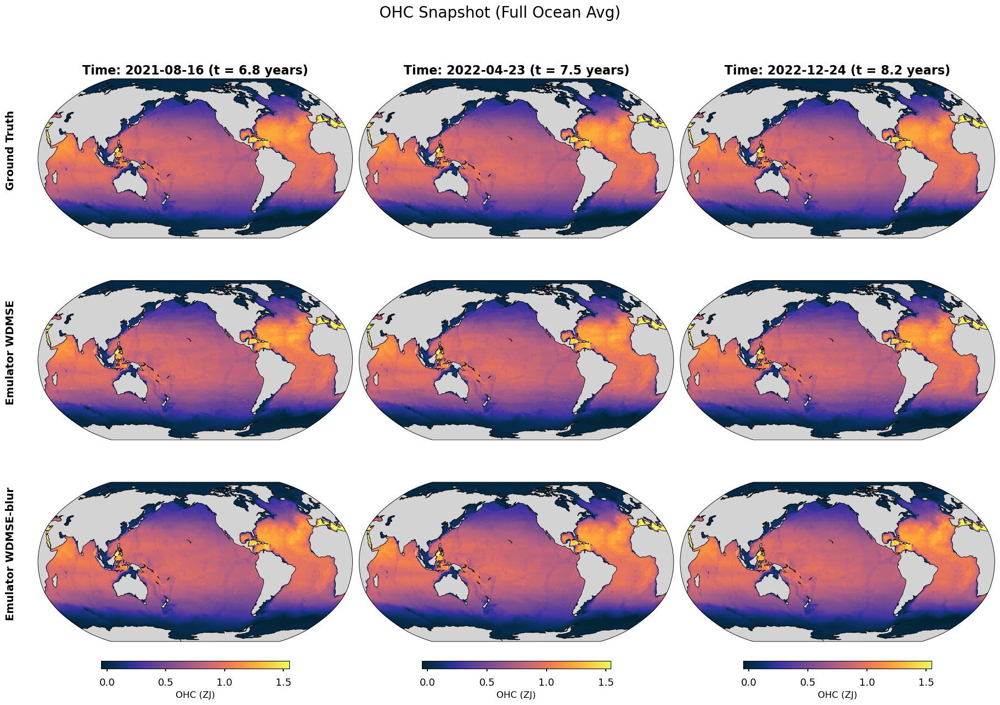

In [23]:
# --------------------------------------------------------------------------------
# BLOCK 15: Snapshots of heat content maps
# --------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import xarray as xr
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Constants
RHO = 1035          # kg/m^3
CP = 3850           # J/(kg K)
SCALE_GJ = 1e21      # Scale to Gigajoules (10^9 J)

VARIABLE_TO_PLOT = 'thetao'

TIME_INDICES = [-100, -50, -1]   # Index of time steps to plot (e.g. Initial, Short, Long)


def calculate_ohc_snapshot_map(dataset, dz, wet_mask, min_depth, max_depth, time_index):
    """
    Calculates the Time-Mean OHC map (Vertically Integrated).
    Formula: Sum(rho * cp * thetao * dz) / Scale
    Units: GJ/m^2
    """
    # Select slices
    thetao_slice = dataset['thetao'].sel(lev=slice(min_depth, max_depth))
    dz_slice = dz.sel(lev=slice(min_depth, max_depth))
    wet_slice = wet_mask.sel(lev=slice(min_depth, max_depth))
    
    # 1. Integrate Vertically (Sum over lev)
    # Result is (time, y, x)
    ohc_integrated = (RHO * CP * thetao_slice * dz_slice *dataset['areacello']* wet_slice).sum('lev')
    
    # 2. Time snapshot
    ohc_mean = ohc_integrated.isel(time=time_index)
    
    # 3. Scale
    return ohc_mean / SCALE_GJ



def plot_ohc_snapshot_comparison(ds_truth, emulators_dict, var_name, time_indices, depth_config):
    """
    Generates a grid of snapshot maps:
    Rows: Datasets
    Cols: Time Indices
    """
    config = VAR_CONFIG.get(var_name, {'cmap': 'viridis', 'units': '', 'label': var_name, 'centered': False})
    units = config['units']
    
    print(f"Preparing Snapshot Maps for OHC ({depth_config['title']})...")
    
    # Setup Metrics from Truth
    dz_truth = ds_truth['dz']
    
    # Determine dimensionality for mask
    if 'lev' in ds_truth[var_name].dims:
        wet_mask = (ds_truth[var_name].isel(time=0) * 0 + 1).compute()
    else:
        # For 2D vars like zos, check for 2D or 3D mask availability
        # Fallback to simple NaN check on the 2D variable itself
        wet_mask = (ds_truth[var_name].isel(time=0) * 0 + 1).compute()

    # Pre-Compute Maps
    # Structure: maps[dataset_label][time_index]
    maps_data = {}
    datasets = [TRUTH_LABEL] + list(emulators_dict.keys())
    
    # 1. Truth
    maps_data[TRUTH_LABEL] = {}
    for t in time_indices:
        maps_data[TRUTH_LABEL][t] = calculate_ohc_snapshot_map(
            ds_truth, dz_truth, wet_mask, 
            depth_config['min'], depth_config['max'], t
        )
        
    # 2. Emulators
    for label, emu_data in emulators_dict.items():
        ds_emu = emu_data['ds']
        maps_data[label] = {}
        for t in time_indices:
            # Note: Using Truth's dz and wet_mask for consistency
            maps_data[label][t] = calculate_ohc_snapshot_map(
                ds_emu, dz_truth, wet_mask, 
                depth_config['min'], depth_config['max'], t
            )

    # --- Plotting ---
    nrows = len(datasets)
    ncols = len(time_indices)
    
    fig, axes = plt.subplots(
        nrows, ncols, 
        figsize=(6 * ncols, 4 * nrows),
        subplot_kw={'projection': ccrs.Robinson(central_longitude=210)},
        constrained_layout=True
    )
    
    if nrows == 1: axes = np.expand_dims(axes, 0)
    if ncols == 1: axes = np.expand_dims(axes, 1)

    cmap = config['cmap']
    
    # Iterate Column-by-Column (Time Steps) to lock colorbars
    for j, t_idx in enumerate(time_indices):
        
        # Determine Range based on TRUTH at this timestep
        truth_slice = maps_data[TRUTH_LABEL][t_idx].values
        valid_data = truth_slice[~np.isnan(truth_slice)]
        
        if len(valid_data) > 0:
            if config['centered']:
                # Centered Colorbar (e.g. Velocity, SSH anomaly)
                abs_max = np.percentile(np.abs(valid_data), 99.75)
                vmin, vmax = -abs_max, abs_max
            else:
                # Sequential Colorbar (e.g. Temperature)
                vmin = np.percentile(valid_data, .25)
                vmax = np.percentile(valid_data, 99.75)
        else:
            vmin, vmax = 0, 1
            
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        
        # Retrieve actual time string for title
        try:
            time_val = ds_truth.time[t_idx].values
            # Format nicely if it's datetime/cftime
            if hasattr(time_val, 'strftime'):
                time_str = time_val.strftime("%Y-%m-%d")
            else:
                time_str = str(time_val)[:10]
        except:
            time_str = f"Index {t_idx}"


        try:
            # Extract raw values to handle both numpy and cftime objects
            t0_val = ds_truth.time.values[0]
            ti_val = ds_truth.time.values[t_idx]
            
            delta = ti_val - t0_val
            
            # Convert to days
            if isinstance(delta, np.timedelta64):
                # Convert from nanoseconds (default for xarray/numpy) to days
                days_elapsed = float(delta) / (1e9 * 86400)
            else:
                # Assume datetime.timedelta (cftime)
                days_elapsed = delta.days + delta.seconds / 86400.0
            
            if days_elapsed < 365:
                day_str = f"t = {int(days_elapsed)} days"
            else:
                years = days_elapsed / 365
                day_str = f"t = {years:.1f} years"
        except:
            day_str = f"Index {t_idx}"

        
        # Iterate Row-by-Row (Datasets)
        for i, ds_name in enumerate(datasets):
            ax = axes[i, j]
            data_to_plot = maps_data[ds_name][t_idx]
            
            p = data_to_plot.plot.pcolormesh(
                ax=ax, transform=ccrs.PlateCarree(),
                x='x', y='y',
                cmap=cmap, norm=norm,
                add_colorbar=False,
                rasterized=True
            )
            
            ax.add_feature(cfeature.LAND, zorder=10, edgecolor='black', facecolor='lightgray')
            ax.coastlines(zorder=11)
            
            # Titles
            if i == 0:
                ax.set_title(f"Time: {time_str} ({day_str})", fontsize=16, fontweight='bold')
            else:
                ax.set_title("")
                
            # Row Labels
            if j == 0:
                label_text = "Ground Truth" if ds_name == TRUTH_LABEL else ds_name
                ax.text(-0.07, 0.55, label_text, va='center', ha='right',
                        rotation='vertical', transform=ax.transAxes, 
                        fontsize=14, fontweight='bold')

        # Add Colorbar for this Time Step
        cbar = fig.colorbar(
            p, ax=axes[:, j], 
            orientation='horizontal', 
            shrink=0.6, pad=0.03, aspect=25
        )
        cbar.set_label(f"OHC (ZJ)", fontsize=12)

    main_title = f"OHC Snapshot"
    if 'lev' in ds_truth[var_name].dims:
        main_title += f" ({depth_config['title']} Avg)"
        
    fig.suptitle(main_title, fontsize=20, y=1.05)
    plt.show()

# --- Execution ---
plot_ohc_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_SLICES[0]
)
plot_ohc_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_SLICES[1]
)
plot_ohc_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_SLICES[2]
)
plot_ohc_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_SLICES[3]
)

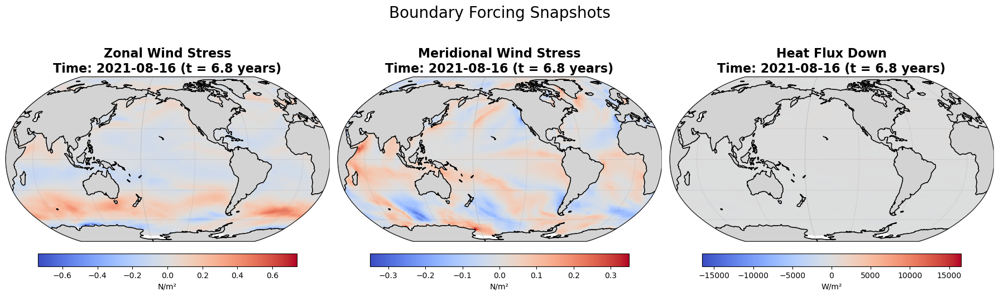

In [43]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr

# --- 配置 ---
# 选择你要画的数据源：真实数据 (data_truth_ocean) 或 模拟数据 (data_ocean_1)
ds_source = data_truth_ocean 

# 要画的边界变量列表
boundary_vars = ['tauuo', 'tauvo', 'hfds']
# 对应单位和标题
var_info = {
    'tauuo': {'label': 'Zonal Wind Stress', 'units': 'N/m²'},
    'tauvo': {'label': 'Meridional Wind Stress', 'units': 'N/m²'},
    'hfds':  {'label': 'Heat Flux Down', 'units': 'W/m²'}
}

# 选择时间步 (例如第 0 步)
time_step_index = -100
t_idx = time_step_index

# --- 绘图代码 ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5), subplot_kw={'projection': ccrs.Robinson(central_longitude=210)})

# Retrieve actual time string for title
try:
    time_val = ds_source.time[time_step_index].values
    # Format nicely if it's datetime/cftime
    if hasattr(time_val, 'strftime'):
        time_str = time_val.strftime("%Y-%m-%d")
    else:
        time_str = str(time_val)[:10]
except:
    time_str = f"Index {time_step_index}"

try:
    # Extract raw values to handle both numpy and cftime objects
    t0_val = ds_source.time.values[0]
    ti_val = ds_source.time.values[t_idx]
    
    delta = ti_val - t0_val
    
    # Convert to days
    if isinstance(delta, np.timedelta64):
        # Convert from nanoseconds (default for xarray/numpy) to days
        days_elapsed = float(delta) / (1e9 * 86400)
    else:
        # Assume datetime.timedelta (cftime)
        days_elapsed = delta.days + delta.seconds / 86400.0
    
    if days_elapsed < 365:
        day_str = f"t = {int(days_elapsed)} days"
    else:
        years = days_elapsed / 365
        day_str = f"t = {years:.1f} years"
except:
    day_str = f"Index {t_idx}"

for i, var_name in enumerate(boundary_vars):
    ax = axes[i]
    
    if var_name in ds_source:
        data_2d = ds_source[var_name].isel(time=time_step_index).squeeze()
        
        
        p = data_2d.plot.pcolormesh(
            ax=ax, transform=ccrs.PlateCarree(),
            x='x', y='y',
            cmap='coolwarm', # 风应力用 coolwarm 比较合适 (正负)
            add_colorbar=True,
            cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.8, 'pad': 0.05, 'label': var_info.get(var_name, {}).get('units', '')}
        )
        
        #ax.set_title(f"{var_info.get(var_name, {}).get('label', var_name)} ({time_str})", fontsize=16)
        ax.set_title(f"{var_info.get(var_name, {}).get('label', var_name)}\nTime: {time_str} ({day_str})", fontsize=16, fontweight='bold')
        ax.coastlines()
        ax.add_feature(cfeature.LAND, zorder=10, facecolor='lightgray', edgecolor='black')
        ax.gridlines(draw_labels=False, alpha=0.3)
    else:
        ax.text(0.5, 0.5, f"Variable {var_name}\nnot found in dataset", ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f"{var_name} - Missing")

plt.suptitle(f"Boundary Forcing Snapshots", fontsize=20, y=1.05)
plt.tight_layout()
plt.show()

np.float32(nan)

-0.3 0.3
-0.3 0.3
-0.3 0.3
-0.2 0.2
-0.2 0.2
-0.2 0.2
-200 200
-200 200
-200 200


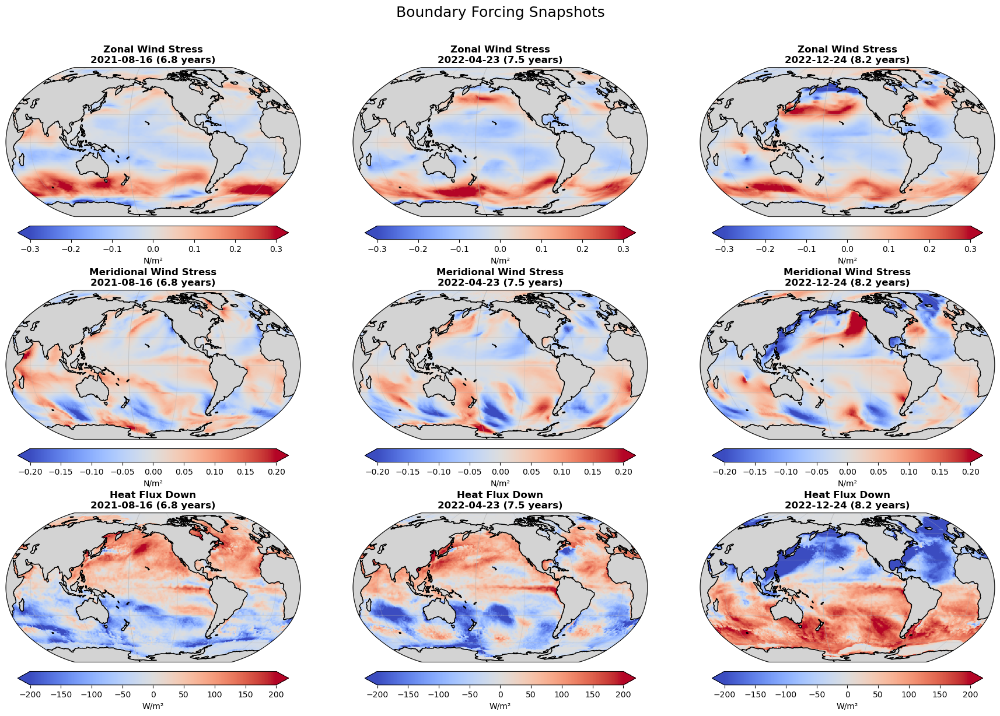

In [67]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
import numpy as np

# --- 配置 ---
ds_source = data_truth_ocean  # 或者 data_ocean_1
boundary_vars = ['tauuo', 'tauvo', 'hfds']
time_indices = [-100, -50, -1]

var_info = {
    'tauuo': {'label': 'Zonal Wind Stress', 'units': 'N/m²'},
    'tauvo': {'label': 'Meridional Wind Stress', 'units': 'N/m²'},
    'hfds':  {'label': 'Heat Flux Down', 'units': 'W/m²'}
}

# --- 绘图初始化 ---
nrows = len(boundary_vars)
ncols = len(time_indices)

fig, axes = plt.subplots(
    nrows, ncols, 
    figsize=(6 * ncols, 4 * nrows), 
    subplot_kw={'projection': ccrs.Robinson(central_longitude=210)}
)

# 确保 axes 是二维数组 (即使只有 1 行或 1 列)
if nrows == 1: axes = np.expand_dims(axes, 0)
if ncols == 1: axes = np.expand_dims(axes, 1)

# --- 循环绘图 ---
for i, var_name in enumerate(boundary_vars):
    for j, t_idx in enumerate(time_indices):
        ax = axes[i, j]
        
        # 1. 动态生成时间标签 (Time & Day String)
        time_str = f"Idx {t_idx}"
        day_str = "?"
        try:
            # 获取时间值
            if hasattr(ds_source, 'time') and len(ds_source.time) > 0:
                # 处理 Python 负索引 (-1 变成 最后一个)
                actual_t_idx = t_idx if t_idx >= 0 else len(ds_source.time) + t_idx
                
                time_val = ds_source.time[actual_t_idx].values
                # 格式化日期字符串
                if hasattr(time_val, 'strftime'):
                    time_str = time_val.strftime("%Y-%m-%d")
                else:
                    time_str = str(time_val)[:10]

                # 计算经过的天数/年数
                t0_val = ds_source.time.values[0]
                ti_val = ds_source.time.values[actual_t_idx]
                delta = ti_val - t0_val
                
                if isinstance(delta, np.timedelta64):
                    days_elapsed = float(delta) / (1e9 * 86400)
                else:
                    days_elapsed = delta.days + delta.seconds / 86400.0
                
                if days_elapsed < 365:
                    day_str = f"{int(days_elapsed)} days"
                else:
                    day_str = f"{days_elapsed/365:.1f} years"
        except Exception as e:
            print(f"Time parsing error at [{i},{j}]: {e}")

        # 2. 提取并绘制数据
        label_text = var_info.get(var_name, {}).get('label', var_name)
        
        if var_name in ds_source:
            try:
                # isel 支持负数索引，所以可以直接传 t_idx
                data_2d = ds_source[var_name].isel(time=t_idx).squeeze()
                data_2d = data_2d.fillna(0) 

                if var_name == 'tauuo':
                    vmin, vmax = -0.3, 0.3
                elif var_name == 'tauvo':
                    vmin, vmax = -0.2, 0.2
                elif var_name == 'hfds':
                    vmin, vmax = -200, 200
                
                p = data_2d.plot.pcolormesh(
                    ax=ax, transform=ccrs.PlateCarree(),
                    x='x', y='y',
                    cmap='coolwarm',
                    vmin=vmin, vmax=vmax,
                    add_colorbar=True,
                    cbar_kwargs={
                        'orientation': 'horizontal', 
                        'shrink': 0.8, 
                        'pad': 0.05, 
                        'label': var_info.get(var_name, {}).get('units', '')
                    },
                )
                ax.coastlines()
                ax.add_feature(cfeature.LAND, zorder=10, facecolor='lightgray', edgecolor='black')
                
                # 设置标题：变量名 + 时间信息
                # 如果你想让每列顶部只显示时间，每行左边只显示变量，可以调整这里
                # 这里默认每个子图都显示完整信息以便阅读
                ax.set_title(f"{label_text}\n{time_str} ({day_str})", fontsize=12, fontweight='bold')
                
            except Exception as e:
                ax.text(0.5, 0.5, f"Error:\n{str(e)}", ha='center', va='center', transform=ax.transAxes)
                ax.set_title(f"{label_text} - Error")
        else:
            ax.text(0.5, 0.5, "Variable Not Found", ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f"{label_text} - Missing")
            
        ax.gridlines(draw_labels=False, alpha=0.3)

# --- 布局调整 ---
plt.suptitle(f"Boundary Forcing Snapshots", fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

array([ 46.37633   ,  30.647182  ,   9.212672  ,   5.911269  ,
        22.754215  ,  39.344063  ,  31.133139  ,  25.610592  ,
        27.351063  ,  44.266678  ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,  25.955692  ,  22.003382  ,
        42.270954  ,  68.61406   ,  67.333786  ,  56.174355  ,
        61.03393   ,  68.11653   ,  75.87893   ,  97.544395  ,
       119.32156   , 121.269455  , 109.56912   , 101.10516   ,
        90.45265   ,  76.19554   ,  64.22476   ,  55.124058  ,
        54.499184  ,  56.96624   ,  55.758522  ,  46.77

In [36]:
emulators_to_analyze['Emulator WDMSE']['ds']['time'].dt.strftime("%Y-%m-%d").shape

(598,)